# Import Library & Load Data

In [2]:
!pip install librosa soundfile shap lime tensorflow scikit-learn seaborn tqdm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=f1732e754253307dad93e8728e451938d3044998973b9a87b07c8269662c6921
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [3]:
import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import IPython.display as ipd # Added this line

import librosa
import librosa.display

from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, BatchNormalization,
    Dropout, Reshape, LSTM, Dense
)
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import shap

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
DATASET_PATH = "/content/drive/MyDrive/MIDTERM TK AI/DATASET"

audio_files = glob.glob(os.path.join(DATASET_PATH, "**", "*.wav"), recursive=True)

print("Jumlah file audio:", len(audio_files))
audio_files[:10]

Jumlah file audio: 2800


['/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_bar_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_bath_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_base_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_back_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_long_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_pain_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_puff_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_neat_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_page_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_jail_angry.wav']

In [6]:
def extract_emotion_from_folder(folder_name):
    folder_name = folder_name.lower().strip()

    emotion_map = {
        "angry": "angry",
        "disgust": "disgust",
        "fear": "fear",
        "happy": "happy",
        "neutral": "neutral",
        "ps": "ps",
        "sad": "sad"
    }

    # contoh folder: OAF_angry, YAF_happy
    parts = folder_name.split("_", 1)
    if len(parts) == 2:
        emotion_part = parts[1]
        if emotion_part in emotion_map:
            return emotion_map[emotion_part]

    return None


def extract_gender_from_folder_or_file(name):
    name = name.upper()
    if name.startswith("OAF"):
        return "male"
    elif name.startswith("YAF"):
        return "female"
    return "unknown"

In [7]:
data = []

for file_path in audio_files:
    folder_name = os.path.basename(os.path.dirname(file_path))
    file_name = os.path.basename(file_path)

    emotion = extract_emotion_from_folder(folder_name)
    gender = extract_gender_from_folder_or_file(folder_name)

    if emotion is not None:
        data.append({
            "emotion": emotion,
            "gender": gender,
            "path": file_path,
            "file_name": file_name,
            "folder": folder_name
        })

df = pd.DataFrame(data)

print("Jumlah data valid:", len(df))
print(df)

Jumlah data valid: 2800
     emotion  gender                                               path  \
0      angry  female  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
1      angry  female  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
2      angry  female  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
3      angry  female  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
4      angry  female  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
...      ...     ...                                                ...   
2795      ps  female  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
2796      ps  female  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
2797      ps  female  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
2798      ps  female  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
2799      ps  female  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   

               file_name     folder  
0      YAF_bar_angry.wav  YAF_angry  

In [8]:
data_path = pd.concat([df], axis = 0)
data_path.to_csv("data_path.csv",index=False)
data_path.head()

,emotion,gender,path,file_name,folder
0,angry,female,/content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...,YAF_bar_angry.wav,YAF_angry
1,angry,female,/content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...,YAF_bath_angry.wav,YAF_angry
2,angry,female,/content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...,YAF_base_angry.wav,YAF_angry
3,angry,female,/content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...,YAF_back_angry.wav,YAF_angry
4,angry,female,/content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...,YAF_long_angry.wav,YAF_angry


#DATA VISUALIZATION & EXPLORATION

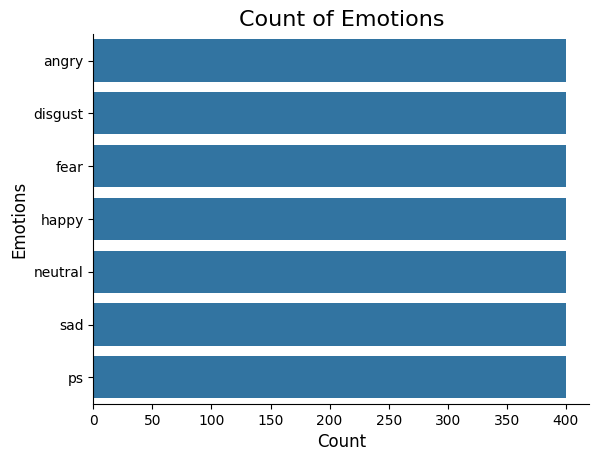

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.title('Count of Emotions', size=16)
sns.countplot(data_path.emotion)
plt.ylabel('Emotions', size=12)
plt.xlabel('Count', size=12)
sns.despine(top=True, right=True, left=False, bottom=False)
plt.show()

In [10]:
data,sr = librosa.load(audio_files[0])
sr

22050

In [11]:
ipd.Audio(data,rate=sr)

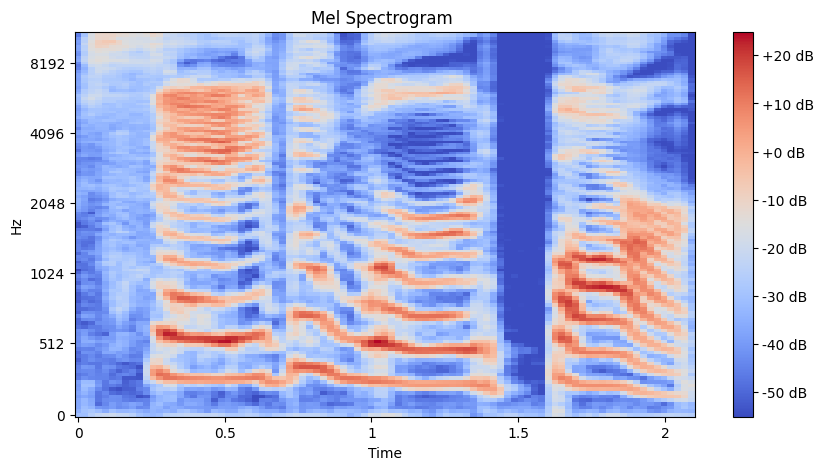

In [12]:
# LOG MEL SPECTROGRAM
plt.figure(figsize=(10, 5))
spectrogram = librosa.feature.melspectrogram(y=data, sr=sr, n_mels=128,fmax=8000)
log_spectrogram = librosa.power_to_db(spectrogram)
librosa.display.specshow(log_spectrogram, y_axis='mel', sr=sr, x_axis='time');
plt.title('Mel Spectrogram ')
plt.colorbar(format='%+2.0f dB')

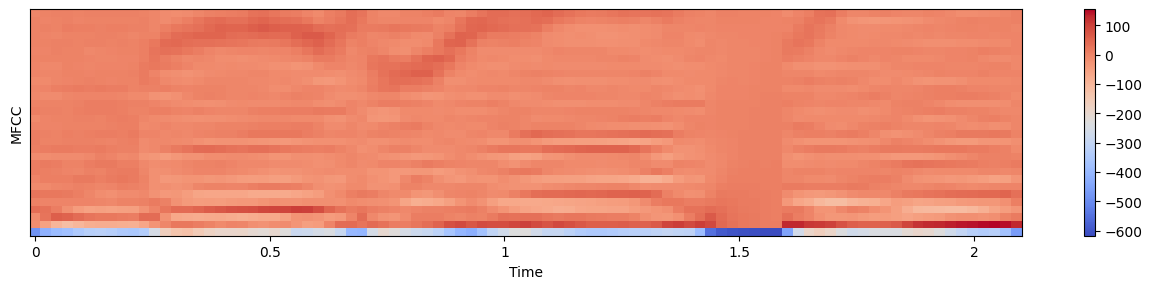

In [13]:
mfcc = librosa.feature.mfcc(y=data, sr=sr, n_mfcc=30)


# MFCC
plt.figure(figsize=(16, 10))
plt.subplot(3,1,1)
librosa.display.specshow(mfcc, x_axis='time')
plt.ylabel('MFCC')
plt.colorbar()

ipd.Audio(data,rate=sr)

#DATA AUGMENTATION

In [14]:
# NOISE
def noise(data):
    noise_amp = 0.035*np.random.uniform()*np.amax(data)
    data = data + noise_amp*np.random.normal(size=data.shape[0])
    return data

# STRETCH
def stretch(data, rate=0.8):
    return librosa.effects.time_stretch(y=data, rate=rate)
# SHIFT
def shift(data):
    shift_range = int(np.random.uniform(low=-5, high = 5)*1000)
    return np.roll(data, shift_range)
# PITCH
def pitch(data, sampling_rate, pitch_factor=0.7):
    return librosa.effects.pitch_shift(y=data, sr=sampling_rate, n_steps=pitch_factor)

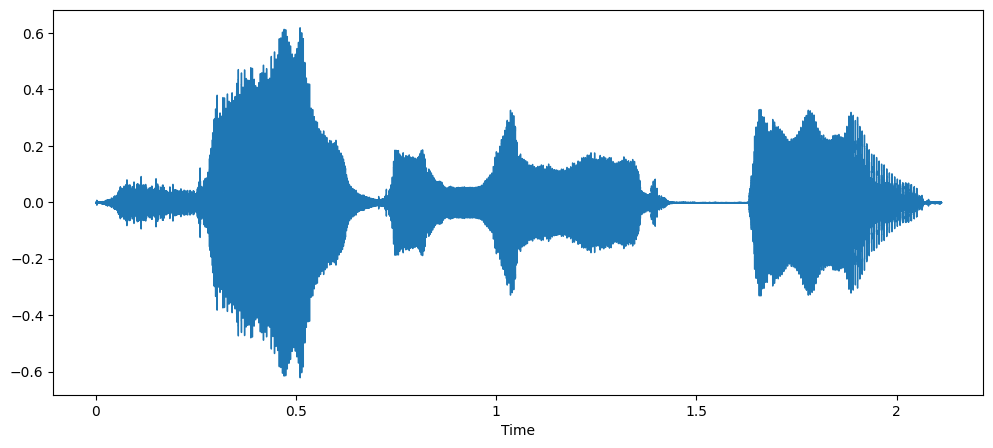

In [15]:
# NORMAL AUDIO

import librosa.display
plt.figure(figsize=(12, 5))
librosa.display.waveshow(y=data, sr=sr)
ipd.Audio(data,rate=sr)

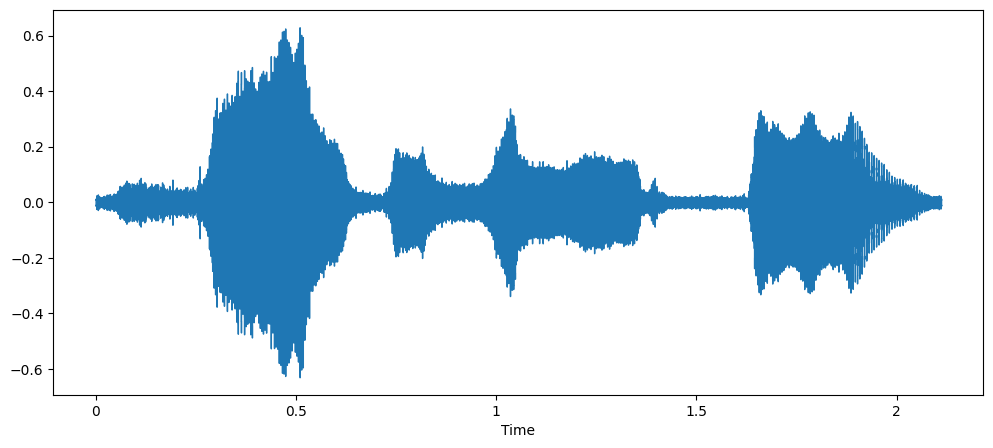

In [16]:
# AUDIO WITH NOISE
x = noise(data)
plt.figure(figsize=(12,5))
librosa.display.waveshow(y=x, sr=sr)
ipd.Audio(x, rate=sr)

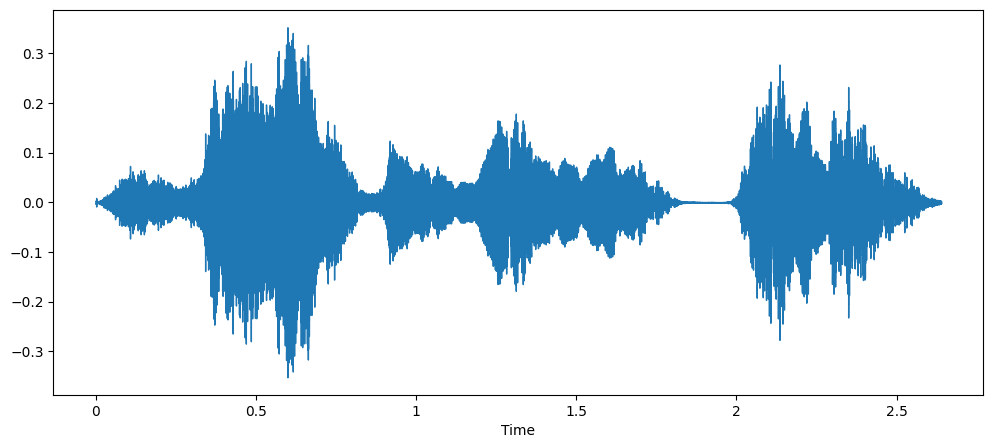

In [17]:
# STRETCHED AUDIO
x = stretch(data)
plt.figure(figsize=(12, 5))
librosa.display.waveshow(y=x, sr=sr)
ipd.Audio(x, rate=sr)

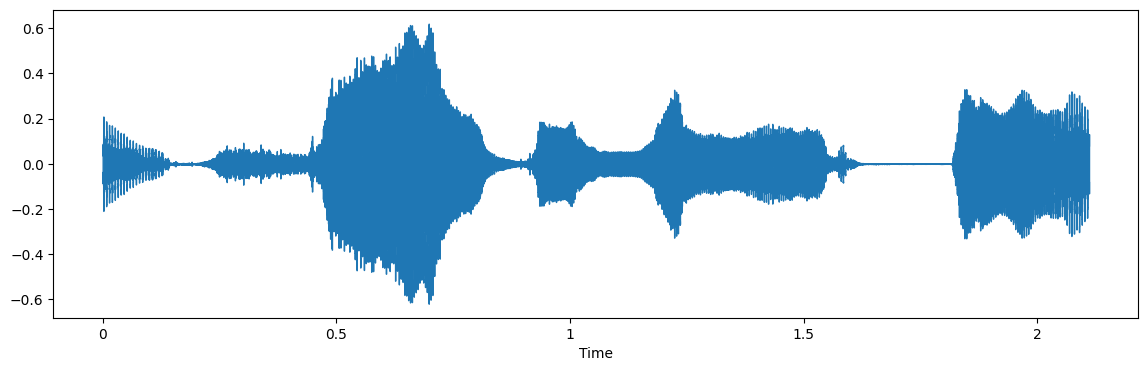

In [18]:
#SHIFTED
x = shift(data)
plt.figure(figsize=(14,4))
librosa.display.waveshow(y=x, sr=sr)
ipd.Audio(x, rate=sr)

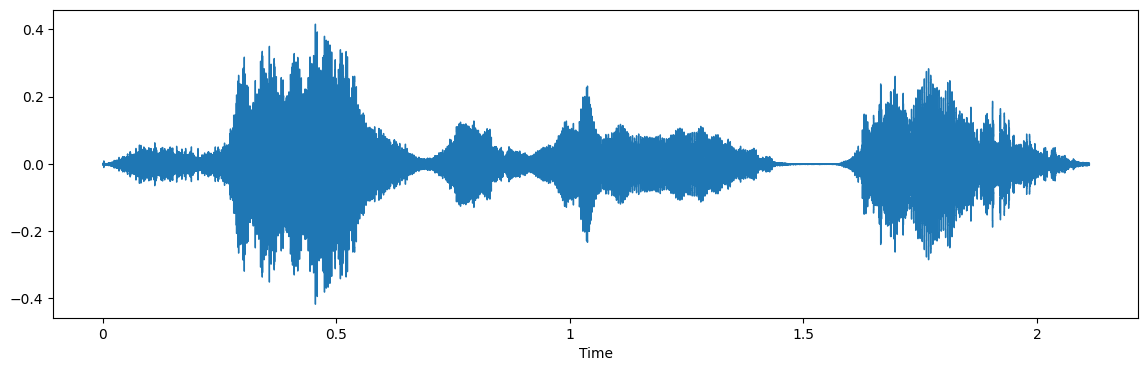

In [19]:
#PITCH
x = pitch(data, sampling_rate=sr)
plt.figure(figsize=(14,4))
librosa.display.waveshow(y=x, sr=sr)
ipd.Audio(x, rate=sr)

# Feature Extraction

In [20]:
def extract_features(data, sample_rate):

    # Chroma_stft
    stft = np.abs(librosa.stft(data))
    chroma_stft = np.mean(librosa.feature.chroma_stft(S=stft, sr=sample_rate).T, axis=0)
    result = chroma_stft # Initialize result with the first feature

    # MFCC
    mfcc = np.mean(librosa.feature.mfcc(y=data, sr=sample_rate).T, axis=0)
    result = np.hstack((result, mfcc)) # stacking horizontally

    # MelSpectogram
    mel = np.mean(librosa.feature.melspectrogram(y=data, sr=sample_rate).T, axis=0)
    result = np.hstack((result, mel)) # stacking horizontally

    return result

def get_features(path):
    # duration and offset are used to take care of the no audio in start and the ending of each audio files as seen above.
    data, sample_rate = librosa.load(path, duration=2.5, offset=0.6)

    # without augmentation
    res1 = extract_features(data, sample_rate)
    result = np.array(res1)

    # data with noise
    noise_data = noise(data)
    res2 = extract_features(noise_data, sample_rate)
    result = np.vstack((result, res2)) # stacking vertically

    # data with stretching and pitching
    new_data = stretch(data)
    data_stretch_pitch = pitch(new_data, sample_rate)
    res3 = extract_features(data_stretch_pitch, sample_rate)
    result = np.vstack((result, res3)) # stacking vertically

    return result

In [21]:
X, Y = [], []
for path, emotion in zip(data_path.path, data_path.emotion):
    feature = get_features(path)
    for ele in feature:
        X.append(ele)
        # appending emotion 3 times as we have made 3 augmentation techniques on each audio file.
        Y.append(emotion)

In [22]:
len(X), len(Y), data_path.path.shape

(8400, 8400, (2800,))

In [23]:
Features = pd.DataFrame(X)
Features['labels'] = Y
Features.to_csv('features.csv', index=False)
Features.head()

,0,1,2,3,4,5,6,7,8,9,...,151,152,153,154,155,156,157,158,159,labels
0,0.484261,0.472583,0.419811,0.429196,0.541090,0.409879,0.370924,0.442590,0.491853,0.556322,...,0.002057,0.001985,0.000985,0.000504,0.000490,0.000255,0.000154,0.000081,0.000007,angry
1,0.505039,0.493865,0.446186,0.458592,0.582262,0.452577,0.374962,0.441299,0.481435,0.559933,...,0.002189,0.002104,0.001109,0.000621,0.000629,0.000385,0.000285,0.000201,0.000124,angry
2,0.503447,0.508950,0.444508,0.378688,0.424286,0.483909,0.334746,0.394293,0.424527,0.503157,...,0.000567,0.000472,0.000547,0.000301,0.000179,0.000140,0.000121,0.000032,0.000003,angry
3,0.554774,0.623357,0.533859,0.491037,0.535549,0.491606,0.470949,0.491760,0.515855,0.670721,...,0.001866,0.000934,0.000672,0.000317,0.000252,0.000145,0.000126,0.000079,0.000006,angry
4,0.625437,0.671838,0.608732,0.611961,0.662873,0.564253,0.567734,0.572239,0.632258,0.720354,...,0.003645,0.002332,0.002155,0.001792,0.001655,0.001627,0.001615,0.001662,0.001489,angry


#DATA PREPARATION

In [24]:
X = Features.iloc[: ,:-1].values
Y = Features['labels'].values

In [25]:
# As this is a multiclass classification problem onehotencoding our Y.
encoder = OneHotEncoder()
Y = encoder.fit_transform(np.array(Y).reshape(-1,1)).toarray()

## Split per file (perbaikan)

Versi sebelumnya membagi seluruh baris secara acak, sehingga versi augmentasi (noise, stretch+pitch) dari file yang sama bisa berada di data latih dan data uji sekaligus (data leakage). Pada versi ini:

- Data dibagi **per file asli** terlebih dahulu: uji 25%, validasi 15% dari sisanya, sisanya latih.
- Augmentasi (3 versi per file) hanya dipakai di **data latih**. Data validasi dan uji hanya berisi versi asli.
- Data validasi dipakai untuk early stopping, sehingga data uji tidak ikut menentukan proses training.

In [26]:
from sklearn.model_selection import train_test_split

# Setiap file asli menghasilkan 3 baris berurutan: [asli, noise, stretch+pitch]
N_AUG = 3
assert len(X) % N_AUG == 0
n_files  = len(X) // N_AUG
y_file   = Y[::N_AUG].argmax(axis=1)      # label tiap file asli
file_ids = np.arange(n_files)

# 1) pisahkan file uji (25%) dulu
trainval_f, test_f = train_test_split(
    file_ids, test_size=0.25, stratify=y_file, random_state=0
)
# 2) dari sisanya, pisahkan file validasi (15%) untuk early stopping
train_f, val_f = train_test_split(
    trainval_f, test_size=0.15, stratify=y_file[trainval_f], random_state=0
)

def rows_all(files):    # semua versi: asli + augmentasi
    return np.concatenate([np.arange(f * N_AUG, f * N_AUG + N_AUG) for f in files])

def rows_orig(files):   # hanya versi asli
    return np.array(files) * N_AUG

train_idx = rows_all(train_f)    # latih: 3 versi per file
val_idx   = rows_orig(val_f)     # validasi: hanya asli
test_idx  = rows_orig(test_f)    # uji: hanya asli

x_train, y_train = X[train_idx], Y[train_idx]
x_val,   y_val   = X[val_idx],   Y[val_idx]
x_test,  y_test  = X[test_idx],  Y[test_idx]

# Cek: tidak ada file yang sama di dua split
assert not (set(train_f) & set(val_f))
assert not (set(train_f) & set(test_f))
assert not (set(val_f) & set(test_f))
print(x_train.shape, x_val.shape, x_test.shape)   # perkiraan: (5355, 160) (315, 160) (700, 160)

(5355, 160) (315, 160) (700, 160)


In [27]:
# scaling: fit hanya di data latih, lalu terapkan ke validasi dan uji
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_val   = scaler.transform(x_val)
x_test  = scaler.transform(x_test)

# membuat data kompatibel dengan model (tambah dimensi channel)
x_train = np.expand_dims(x_train, axis=2)
x_val   = np.expand_dims(x_val,   axis=2)
x_test  = np.expand_dims(x_test,  axis=2)
print(x_train.shape, x_val.shape, x_test.shape)

(5355, 160, 1) (315, 160, 1) (700, 160, 1)


#BASELINE SVM

In [28]:
from sklearn.svm import SVC

# SVM tidak menerima one-hot encoding, gunakan label integer
y_train_int = np.argmax(y_train, axis=1)
y_test_int  = np.argmax(y_test, axis=1)

# SVM memerlukan 2D input, squeeze dimensi ke-3
x_train_svm = x_train.squeeze(axis=2)  # shape: (samples, features)
x_test_svm  = x_test.squeeze(axis=2)

# Training SVM dengan RBF kernel
print("Training SVM... (ini mungkin butuh beberapa menit)")
svm_model = SVC(kernel='rbf', C=10, gamma='scale', decision_function_shape='ovr', random_state=42, probability=True)
svm_model.fit(x_train_svm, y_train_int)
print("Training SVM selesai!")

Training SVM... (ini mungkin butuh beberapa menit)
Training SVM selesai!


In [29]:
# Prediksi SVM
y_pred_svm = svm_model.predict(x_test_svm)

# Metrics
acc_svm   = accuracy_score(y_test_int, y_pred_svm)
prec_svm  = precision_score(y_test_int, y_pred_svm, average='weighted')
rec_svm   = recall_score(y_test_int, y_pred_svm, average='weighted')
f1_svm    = f1_score(y_test_int, y_pred_svm, average='weighted')

# Get label names from the encoder
label_names = encoder.categories_[0]

print("======= SVM (Baseline) Results ======")
print(f"Accuracy  : {acc_svm:.4f}")
print(f"Precision : {prec_svm:.4f}")
print(f"Recall    : {rec_svm:.4f}")
print(f"F1-Score  : {f1_svm:.4f}")
print()
print("Classification Report:")
print(classification_report(y_test_int, y_pred_svm, target_names=label_names))

======= SVM (Baseline) Results ======
Accuracy  : 0.9629
Precision : 0.9658
Recall    : 0.9629
F1-Score  : 0.9630

Classification Report:
              precision    recall  f1-score   support

       angry       0.99      0.88      0.93       100
     disgust       0.99      0.97      0.98       100
        fear       0.86      1.00      0.93       100
       happy       0.98      0.93      0.95       100
     neutral       0.99      1.00      1.00       100
          ps       0.95      0.97      0.96       100
         sad       1.00      0.99      0.99       100

    accuracy                           0.96       700
   macro avg       0.97      0.96      0.96       700
weighted avg       0.97      0.96      0.96       700



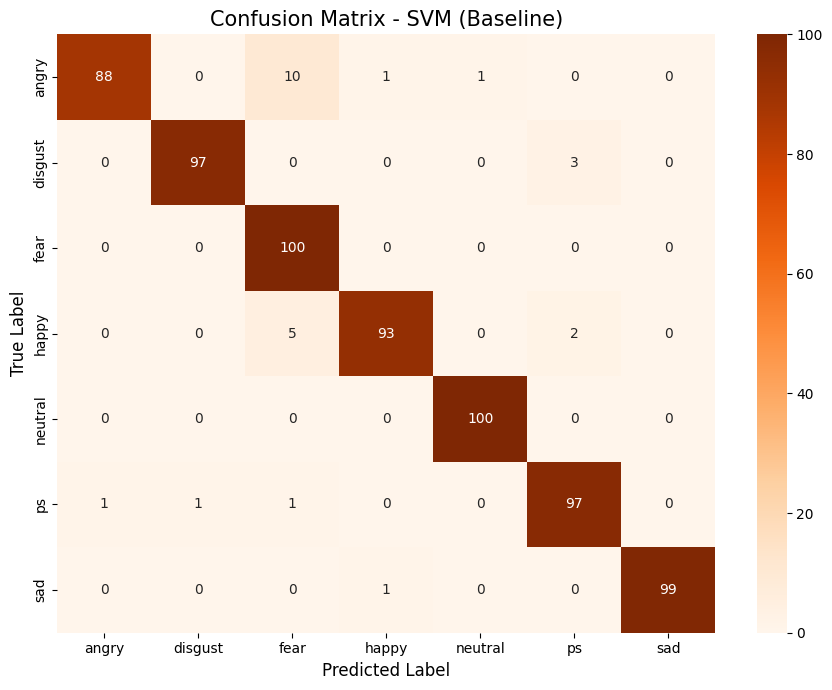

In [30]:
# Confusion Matrix SVM
cm_svm = confusion_matrix(y_test_int, y_pred_svm)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_svm, annot=True, fmt='d', cmap='Oranges',
    xticklabels=label_names, yticklabels=label_names
)
plt.title('Confusion Matrix - SVM (Baseline)', fontsize=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

#CNN LSTM MODEL

In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, LSTM, Dense, Dropout,
    BatchNormalization, Flatten
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

n_classes = y_train.shape[1]  # 7 emosi
input_shape = (x_train.shape[1], 1)  # (n_features, 1)

def build_cnn_lstm(input_shape, n_classes):
    model = Sequential([
        # --- CNN Block 1 ---
        Conv1D(64, kernel_size=3, activation='relu', padding='same', input_shape=input_shape),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.3),

        # --- CNN Block 2 ---
        Conv1D(128, kernel_size=3, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.3),

        # --- LSTM Block ---
        LSTM(128, return_sequences=True),
        Dropout(0.3),
        LSTM(64, return_sequences=False),
        Dropout(0.3),

        # --- Output Block ---
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(n_classes, activation='softmax')
    ])
    return model

cnn_lstm_model = build_cnn_lstm(input_shape, n_classes)
cnn_lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
cnn_lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 160, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 80, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 80, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 80, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 40, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 40, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 40, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 40, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,335 (825.53 KB)

 Trainable params: 210,951 (824.03 KB)

 Non-trainable params: 384 (1.50 KB)

In [32]:
# Callbacks
early_stop = EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True, verbose=1
)
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1
)

# Training
history = cnn_lstm_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 27s 124ms/step - accuracy: 0.2880 - loss: 1.7023 - val_accuracy: 0.1492 - val_loss: 2.3207 - learning_rate: 0.0010
Epoch 2/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 23s 137ms/step - accuracy: 0.4848 - loss: 1.2273 - val_accuracy: 0.1905 - val_loss: 3.0249 - learning_rate: 0.0010
Epoch 3/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 21s 126ms/step - accuracy: 0.6015 - loss: 0.9622 - val_accuracy: 0.4825 - val_loss: 1.6625 - learning_rate: 0.0010
Epoch 4/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 24s 142ms/step - accuracy: 0.7218 - loss: 0.7459 - val_accuracy: 0.7460 - val_loss: 0.8581 - learning_rate: 0.0010
Epoch 5/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 21s 123ms/step - accuracy: 0.8050 - loss: 0.5658 - val_accuracy: 0.8603 - val_loss: 0.4006 - learning_rate: 0.0010
Epoch 6/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 23s 138ms/step - accuracy: 0.8592 - loss: 0.4294 - val_accuracy: 0.9206 - val_loss: 0.2364 - learning_rate: 0.0010
Epoch 7/100
168/168 ━━━━━━━━━━━━━━━━━━━━ 40s 132ms/step - accura

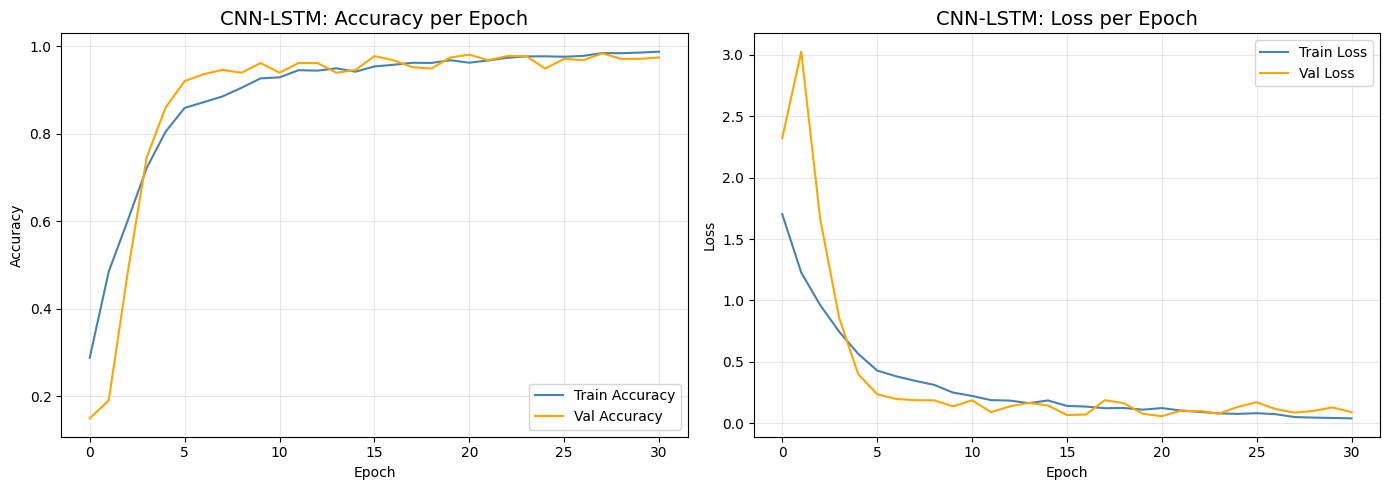

In [33]:
# Plot Training History CNN-LSTM
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy', color='steelblue')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy', color='orange')
axes[0].set_title('CNN-LSTM: Accuracy per Epoch', fontsize=14)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(history.history['loss'], label='Train Loss', color='steelblue')
axes[1].plot(history.history['val_loss'], label='Val Loss', color='orange')
axes[1].set_title('CNN-LSTM: Loss per Epoch', fontsize=14)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Prediksi CNN-LSTM
y_pred_cnn_prob = cnn_lstm_model.predict(x_test)
y_pred_cnn = np.argmax(y_pred_cnn_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

# Decode label names
label_names = encoder.categories_[0]  # ['angry', 'disgust', 'fear', 'happy', 'neutral', 'ps', 'sad']

# Metrics
acc_cnn   = accuracy_score(y_true, y_pred_cnn)
prec_cnn  = precision_score(y_true, y_pred_cnn, average='weighted')
rec_cnn   = recall_score(y_true, y_pred_cnn, average='weighted')
f1_cnn    = f1_score(y_true, y_pred_cnn, average='weighted')

print("======= CNN-LSTM Results =======")
print(f"Accuracy  : {acc_cnn:.4f}")
print(f"Precision : {prec_cnn:.4f}")
print(f"Recall    : {rec_cnn:.4f}")
print(f"F1-Score  : {f1_cnn:.4f}")
print()
print("Classification Report:")
print(classification_report(y_true, y_pred_cnn, target_names=label_names))

22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step
======= CNN-LSTM Results =======
Accuracy  : 0.9814
Precision : 0.9817
Recall    : 0.9814
F1-Score  : 0.9814

Classification Report:
              precision    recall  f1-score   support

       angry       0.99      0.98      0.98       100
     disgust       0.99      0.94      0.96       100
        fear       1.00      1.00      1.00       100
       happy       0.95      0.98      0.97       100
     neutral       0.99      1.00      1.00       100
          ps       0.95      0.97      0.96       100
         sad       1.00      1.00      1.00       100

    accuracy                           0.98       700
   macro avg       0.98      0.98      0.98       700
weighted avg       0.98      0.98      0.98       700



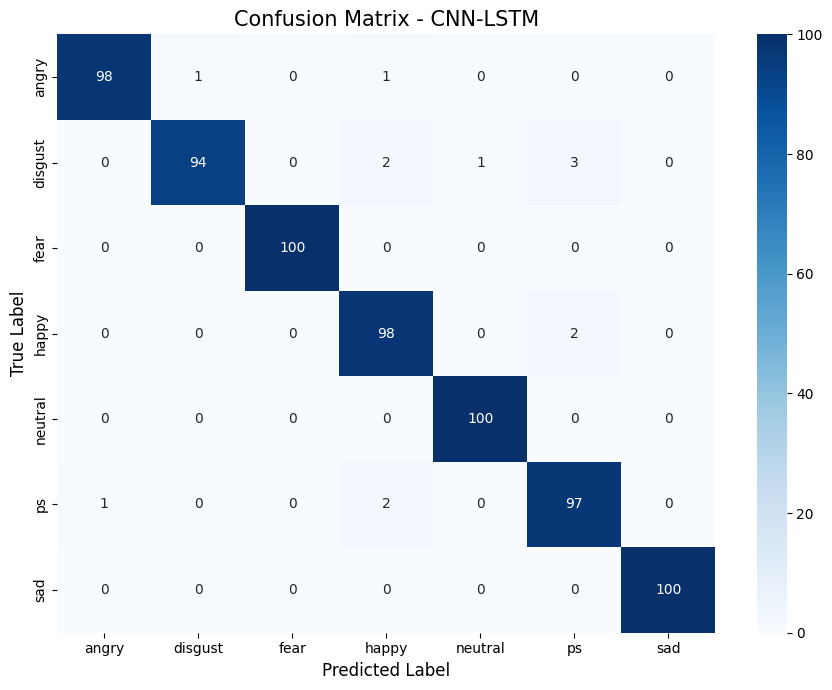

In [35]:
# Confusion Matrix CNN-LSTM
cm_cnn = confusion_matrix(y_true, y_pred_cnn)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_cnn, annot=True, fmt='d', cmap='Blues',
    xticklabels=label_names, yticklabels=label_names
)
plt.title('Confusion Matrix - CNN-LSTM', fontsize=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

#PERBANDINGAN CNN LSTM - SVM

In [36]:
# Tabel perbandingan
comparison_df = pd.DataFrame({
    'Metric'   : ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'CNN-LSTM' : [acc_cnn, prec_cnn, rec_cnn, f1_cnn],
    'SVM'      : [acc_svm, prec_svm, rec_svm, f1_svm]
})
comparison_df = comparison_df.set_index('Metric')
print(comparison_df.round(4).to_string())

           CNN-LSTM     SVM
Metric                     
Accuracy     0.9814  0.9629
Precision    0.9817  0.9658
Recall       0.9814  0.9629
F1-Score     0.9814  0.9630


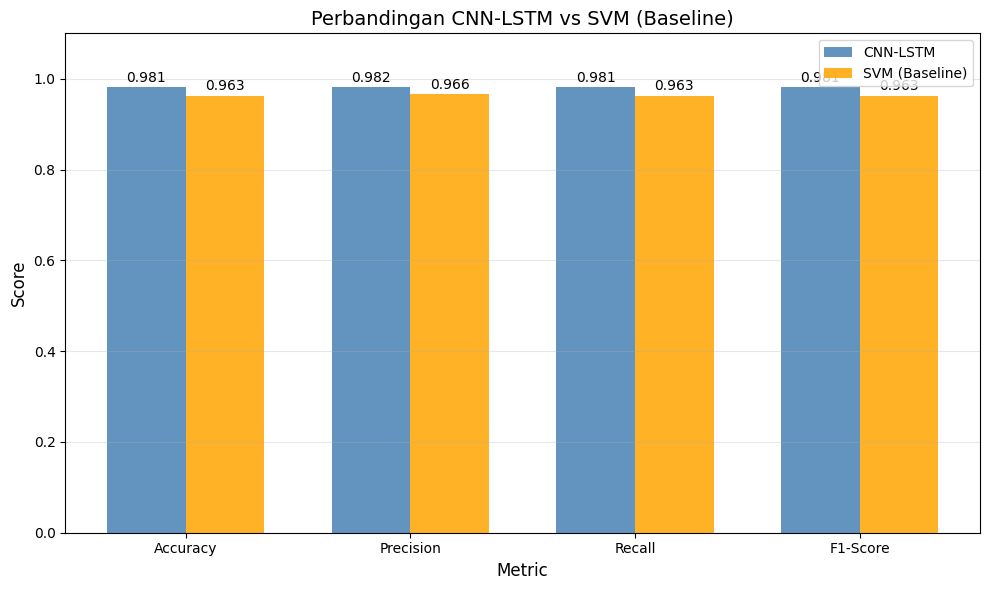

In [37]:
# Bar chart perbandingan
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
cnn_scores = [acc_cnn, prec_cnn, rec_cnn, f1_cnn]
svm_scores = [acc_svm, prec_svm, rec_svm, f1_svm]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, cnn_scores, width, label='CNN-LSTM', color='steelblue', alpha=0.85)
bars2 = ax.bar(x + width/2, svm_scores, width, label='SVM (Baseline)', color='orange', alpha=0.85)

# Nilai di atas bar
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=10)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=10)

ax.set_xlabel('Metric', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Perbandingan CNN-LSTM vs SVM (Baseline)', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

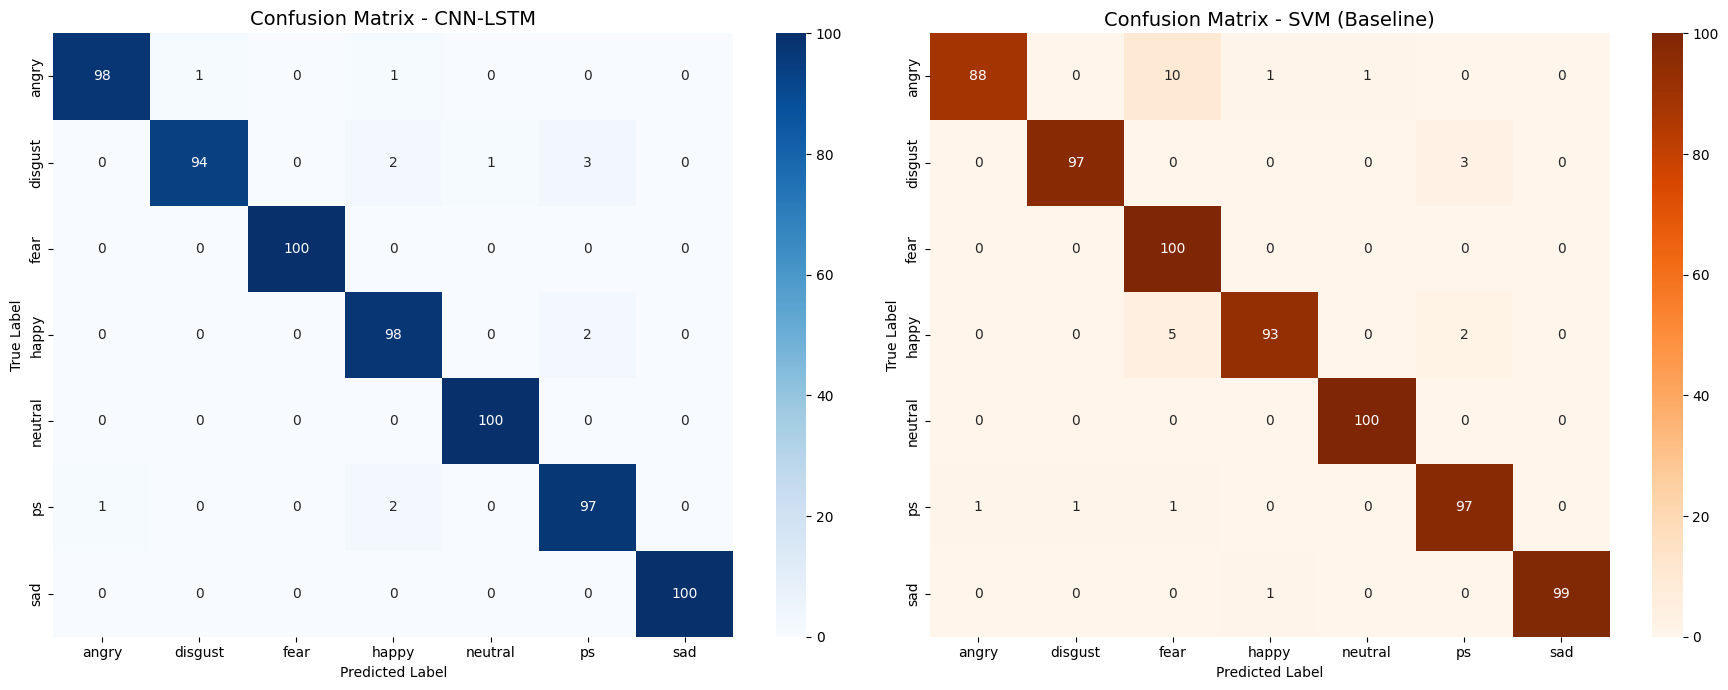

In [38]:
# Confusion Matrix CNN-LSTM dan SVM berdampingan
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    cm_cnn, annot=True, fmt='d', cmap='Blues',
    xticklabels=label_names, yticklabels=label_names, ax=axes[0]
)
axes[0].set_title('Confusion Matrix - CNN-LSTM', fontsize=14)
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

sns.heatmap(
    cm_svm, annot=True, fmt='d', cmap='Oranges',
    xticklabels=label_names, yticklabels=label_names, ax=axes[1]
)
axes[1].set_title('Confusion Matrix - SVM (Baseline)', fontsize=14)
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

#SAVING MODEL

In [39]:
import pickle
import os

SAVE_DIR = "/content/drive/MyDrive/MIDTERM TK AI/model/saved_models_v2"
os.makedirs(SAVE_DIR, exist_ok=True)

# --- Simpan CNN-LSTM ---
cnn_lstm_model.save(os.path.join(SAVE_DIR, 'cnn_lstm_model.h5'))
print("✅ CNN-LSTM model tersimpan")

# --- Simpan SVM ---
with open(os.path.join(SAVE_DIR, 'svm_model.pkl'), 'wb') as f:
    pickle.dump(svm_model, f)
print("✅ SVM model tersimpan")

# --- Simpan Scaler ---
with open(os.path.join(SAVE_DIR, 'scaler.pkl'), 'wb') as f:
    pickle.dump(scaler, f)
print("✅ Scaler tersimpan")

# --- Simpan Encoder ---
with open(os.path.join(SAVE_DIR, 'encoder.pkl'), 'wb') as f:
    pickle.dump(encoder, f)
print("✅ Encoder tersimpan")

print(f"\n📁 Semua file tersimpan di: {SAVE_DIR}")

✅ CNN-LSTM model tersimpan
✅ SVM model tersimpan
✅ Scaler tersimpan
✅ Encoder tersimpan

📁 Semua file tersimpan di: /content/drive/MyDrive/MIDTERM TK AI/model/saved_models_v2


In [40]:
import pickle
import numpy as np
import librosa
import IPython.display as ipd
import matplotlib.pyplot as plt
import librosa.display
from tensorflow.keras.models import load_model

SAVE_DIR = "/content/drive/MyDrive/MIDTERM TK AI/model/saved_models_v2"

# Load CNN-LSTM
cnn_lstm_demo = load_model(os.path.join(SAVE_DIR, 'cnn_lstm_model.h5'))
print("✅ CNN-LSTM loaded")

# Load SVM
with open(os.path.join(SAVE_DIR, 'svm_model.pkl'), 'rb') as f:
    svm_demo = pickle.load(f)
print("✅ SVM loaded")

# Load Scaler
with open(os.path.join(SAVE_DIR, 'scaler.pkl'), 'rb') as f:
    scaler_demo = pickle.load(f)
print("✅ Scaler loaded")

# Load Encoder
with open(os.path.join(SAVE_DIR, 'encoder.pkl'), 'rb') as f:
    encoder_demo = pickle.load(f)
print("✅ Encoder loaded")

LABEL_NAMES = encoder_demo.categories_[0]
print(f"\n🏷️  Kelas emosi: {list(LABEL_NAMES)}")

✅ CNN-LSTM loaded
✅ SVM loaded
✅ Scaler loaded
✅ Encoder loaded

🏷️  Kelas emosi: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'ps', 'sad']


In [41]:
def extract_features(data, sample_rate):
    """Ekstrak MFCC + Chroma + Mel — harus identik dengan saat training."""
    # Chroma
    stft = np.abs(librosa.stft(data))
    chroma = np.mean(librosa.feature.chroma_stft(S=stft, sr=sample_rate).T, axis=0)

    # MFCC
    mfcc = np.mean(librosa.feature.mfcc(y=data, sr=sample_rate).T, axis=0)

    # Mel Spectrogram
    mel = np.mean(librosa.feature.melspectrogram(y=data, sr=sample_rate).T, axis=0)

    return np.hstack((chroma, mfcc, mel))


def get_features_with_augmentation(path):
    """Ekstrak fitur dari 1 file audio (original + 3 augmentasi)."""
    data, sr = librosa.load(path, duration=2.5, offset=0.6)

    f_original = extract_features(data, sr)

    # Augmentasi
    noise_data = data + 0.035 * np.random.uniform() * np.amax(data) * np.random.normal(size=data.shape[0])
    f_noise    = extract_features(noise_data, sr)

    stretched  = librosa.effects.time_stretch(y=data, rate=0.8)
    f_stretch  = extract_features(stretched, sr)

    pitched    = librosa.effects.pitch_shift(y=data, sr=sr, n_steps=0.7)
    f_pitch    = extract_features(pitched, sr)

    return [f_original, f_noise, f_stretch, f_pitch]


def prepare_single_input(path):
    """Ambil fitur original saja (tanpa augmentasi) untuk prediksi 1 file."""
    data, sr = librosa.load(path, duration=2.5, offset=0.6)
    features = extract_features(data, sr)
    return features, data, sr

print("✅ Fungsi feature extraction siap")

✅ Fungsi feature extraction siap



================ PREDICTION RESULTS ================
CNN-LSTM Prediction : ANGRY (99.07%)
SVM Prediction      : DISGUST (53.10%)



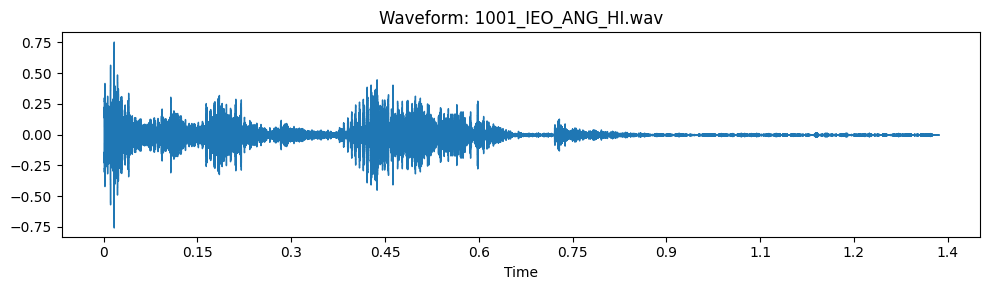

In [42]:
TEST_FILE = "/content/drive/MyDrive/MIDTERM TK AI/TEST/1001_IEO_ANG_HI.wav"

def predict_emotion(audio_path, show_viz=True):
    # 1. Prepare input feature
    features, data, sr = prepare_single_input(audio_path)

    # 2. Scale features using the fitted scaler
    features_scaled = scaler_demo.transform(features.reshape(1, -1))

    # 3. Predict with SVM
    svm_pred_idx = svm_demo.predict(features_scaled)[0]
    svm_pred_label = LABEL_NAMES[svm_pred_idx]
    svm_probs = svm_demo.predict_proba(features_scaled)[0]

    # 4. Predict with CNN-LSTM
    cnn_input = np.expand_dims(features_scaled, axis=2)  # shape: (1, 160, 1)
    cnn_probs = cnn_lstm_demo.predict(cnn_input, verbose=0)[0]
    cnn_pred_idx = np.argmax(cnn_probs)
    cnn_pred_label = LABEL_NAMES[cnn_pred_idx]

    print("\n================ PREDICTION RESULTS ================")
    print(f"CNN-LSTM Prediction : {cnn_pred_label.upper()} ({cnn_probs[cnn_pred_idx]*100:.2f}%)")
    print(f"SVM Prediction      : {svm_pred_label.upper()} ({svm_probs[svm_pred_idx]*100:.2f}%)")
    print("====================================================\n")

    if show_viz:
        # Optional simple visualization of the audio wave
        plt.figure(figsize=(10, 3))
        librosa.display.waveshow(y=data, sr=sr)
        plt.title(f"Waveform: {os.path.basename(audio_path)}")
        plt.tight_layout()
        plt.show()

    return cnn_pred_label, svm_pred_label

# Run the prediction
cnn_result, svm_result = predict_emotion(TEST_FILE, show_viz=True)

#EXPLANABLE AI

#SHAP

In [43]:
# Variabel yang dipakai sel-sel SHAP di bawah
x_train_2d = x_train.squeeze(axis=2)
x_test_2d  = x_test.squeeze(axis=2)
y_true_labels = np.array(label_names)[y_test.argmax(axis=1)]   # label string tiap data uji

FEATURE_NAMES = (
    [f'Chroma_{i+1}' for i in range(12)] +
    [f'MFCC_{i+1}'   for i in range(20)] +
    [f'Mel_{i+1}'    for i in range(128)]
)

def cnn_lstm_predict_proba(x):
    x = np.asarray(x).reshape(-1, 160, 1)
    return cnn_lstm_model.predict(x, verbose=0)

def svm_predict_proba(x):
    return svm_model.predict_proba(np.asarray(x))

In [44]:
N_BACKGROUND = 100
N_EXPLAIN    = 50

np.random.seed(42)
bg_idx   = np.random.choice(len(x_train_2d), N_BACKGROUND, replace=False)
exp_idx  = np.random.choice(len(x_test_2d),  N_EXPLAIN,    replace=False)

x_background = x_train_2d[bg_idx]
x_explain    = x_test_2d[exp_idx]
y_explain    = y_true_labels[exp_idx]

print(f"   Background : {x_background.shape}")
print(f"   Explain    : {x_explain.shape}")

   Background : (100, 160)
   Explain    : (50, 160)


CNN LSTM

In [45]:
shap_explainer_cnn = shap.KernelExplainer(
    model  = cnn_lstm_predict_proba,
    data   = shap.kmeans(x_background, 20)
)

shap_values_cnn_raw = shap_explainer_cnn.shap_values(
    x_explain, nsamples=200, silent=True
)

if isinstance(shap_values_cnn_raw, list):
    shap_values_cnn = np.stack(shap_values_cnn_raw, axis=-1)
else:
    shap_values_cnn = shap_values_cnn_raw

print(f"✅ SHAP CNN-LSTM selesai — shape: {shap_values_cnn.shape}")

✅ SHAP CNN-LSTM selesai — shape: (50, 160, 7)


Shape of shap_values_array: (50, 160, 7)
Shape of global_importance_cnn: (160,)


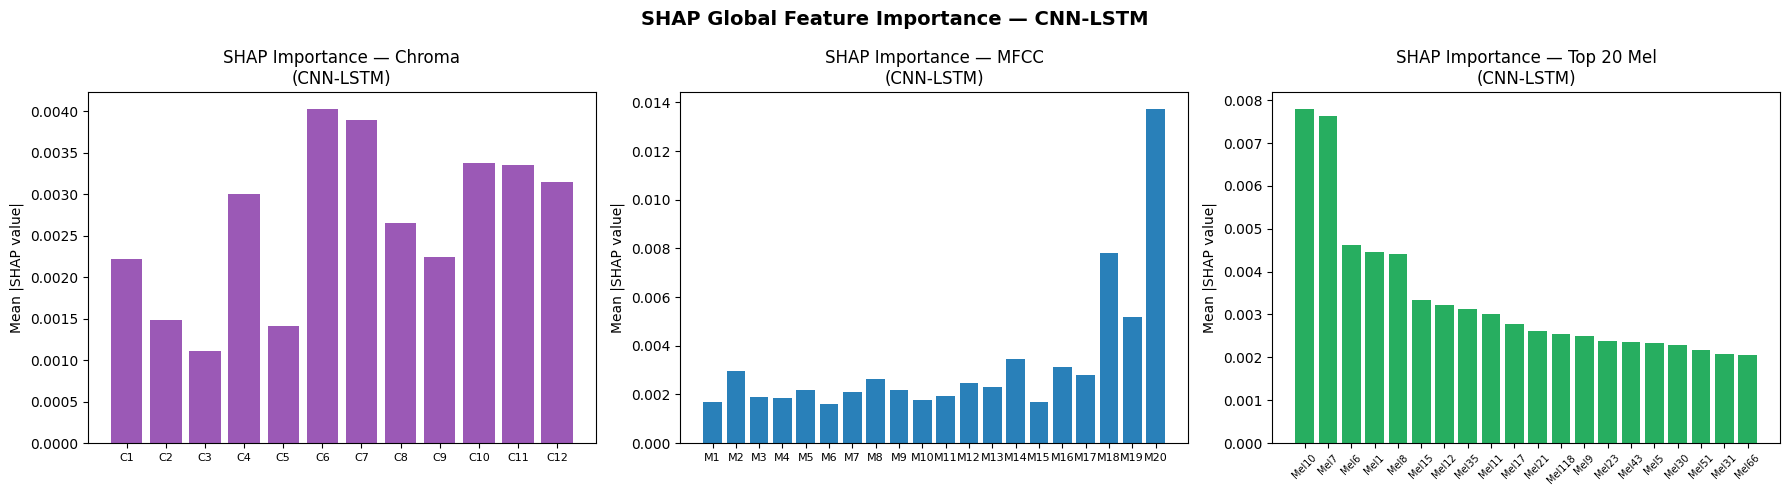


📊 Rata-rata SHAP per kelompok fitur (CNN-LSTM):
   MFCC (20)      : 0.003265
   Chroma (12)    : 0.002658
   Mel (128)      : 0.001521


In [46]:
shap_values_array = np.array(shap_values_cnn)
print(f"Shape of shap_values_array: {shap_values_array.shape}")

global_importance_cnn = np.mean(np.abs(shap_values_array), axis=(0, 2))
print(f"Shape of global_importance_cnn: {global_importance_cnn.shape}")


imp_chroma = global_importance_cnn[:12]
imp_mfcc   = global_importance_cnn[12:32]
imp_mel    = global_importance_cnn[32:]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chroma
axes[0].bar(range(12), imp_chroma, color='#9b59b6')
axes[0].set_xticks(range(12))
axes[0].set_xticklabels([f'C{i+1}' for i in range(12)], fontsize=8)
axes[0].set_title('SHAP Importance — Chroma\n(CNN-LSTM)', fontsize=12)
axes[0].set_ylabel('Mean |SHAP value|')

# MFCC
axes[1].bar(range(20), imp_mfcc, color='#2980b9')
axes[1].set_xticks(range(20))
axes[1].set_xticklabels([f'M{i+1}' for i in range(20)], fontsize=8)
axes[1].set_title('SHAP Importance — MFCC\n(CNN-LSTM)', fontsize=12)
axes[1].set_ylabel('Mean |SHAP value|')

# Top-20 Mel
top20_mel_idx = np.argsort(imp_mel)[-20:][::-1]
axes[2].bar(range(20), imp_mel[top20_mel_idx], color='#27ae60')
axes[2].set_xticks(range(20))
axes[2].set_xticklabels([f'Mel{i+1}' for i in top20_mel_idx], fontsize=7, rotation=45)
axes[2].set_title('SHAP Importance — Top 20 Mel\n(CNN-LSTM)', fontsize=12)
axes[2].set_ylabel('Mean |SHAP value|')

plt.suptitle('SHAP Global Feature Importance — CNN-LSTM', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

group_imp = {
    'Chroma (12)' : imp_chroma.mean(),
    'MFCC (20)'   : imp_mfcc.mean(),
    'Mel (128)'   : imp_mel.mean()
}
print("\n📊 Rata-rata SHAP per kelompok fitur (CNN-LSTM):")
for k, v in sorted(group_imp.items(), key=lambda x: -x[1]):
    print(f"   {k:15s}: {v:.6f}")

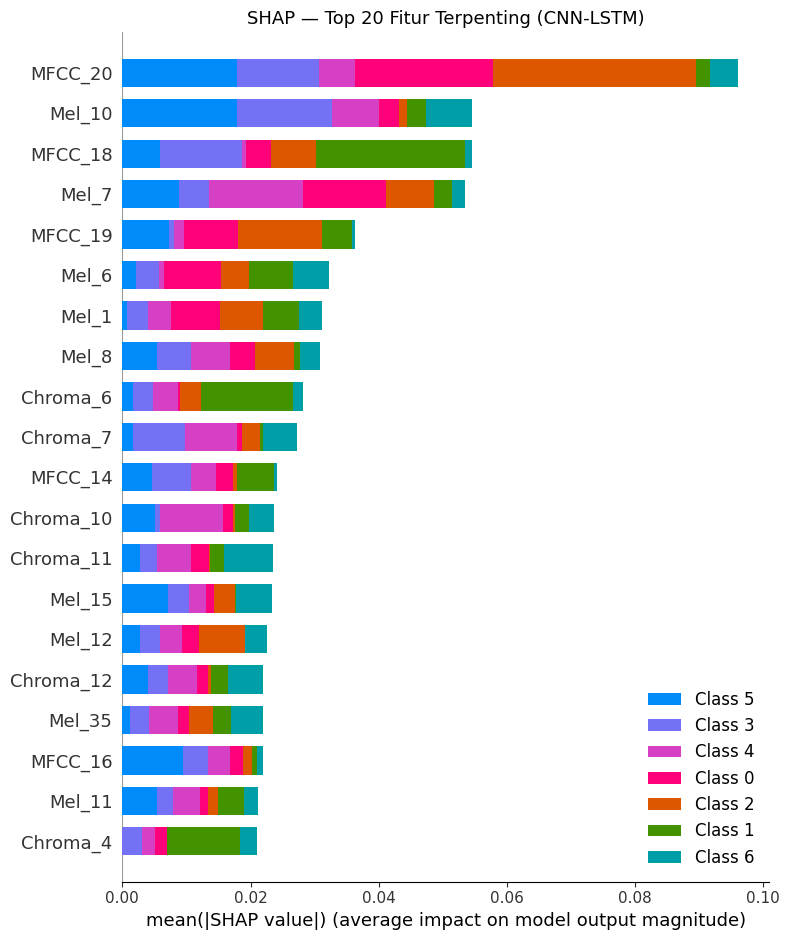

In [47]:
shap_mean_classes = np.mean(np.abs(np.array(shap_values_cnn)), axis=0)  # (n_features, n_classes)

plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values_cnn,
    x_explain,
    feature_names = FEATURE_NAMES,
    max_display   = 20,
    plot_type     = 'bar',
    show          = False
)
plt.title('SHAP — Top 20 Fitur Terpenting (CNN-LSTM)', fontsize=13)
plt.tight_layout()
plt.show()

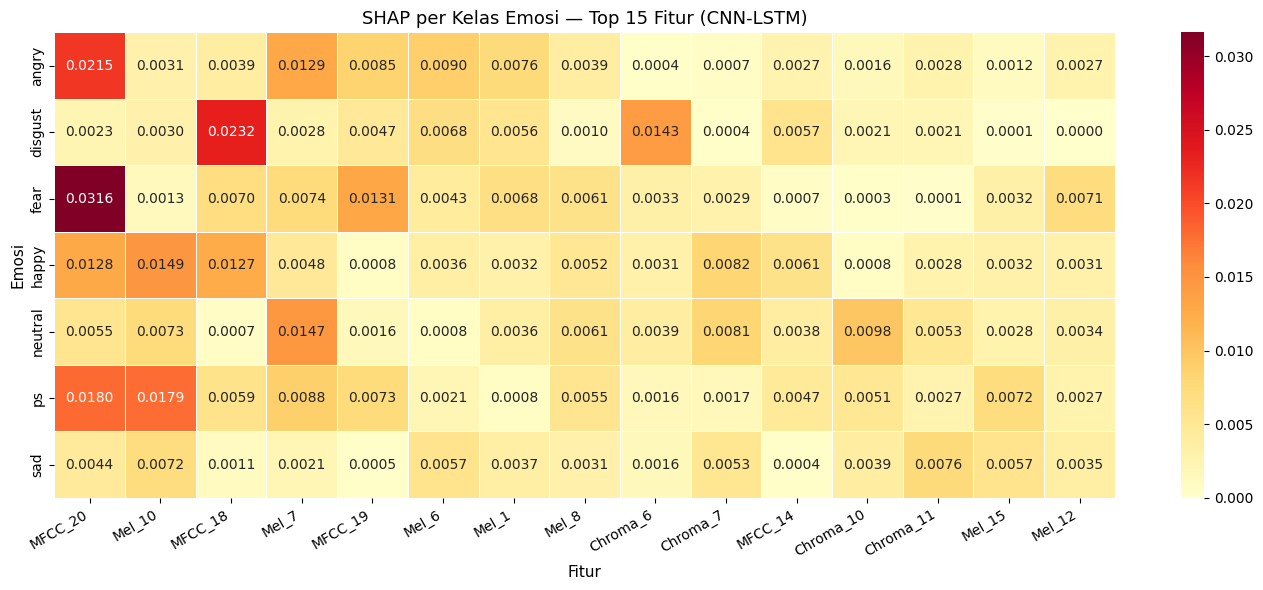

In [48]:
top15_idx = np.argsort(global_importance_cnn)[-15:][::-1]
top15_names = [FEATURE_NAMES[i] for i in top15_idx]


class_importance = np.array([
    np.abs(shap_values_cnn[:, :, c]).mean(axis=0)[top15_idx]
    for c in range(len(LABEL_NAMES))
])  # (n_classes, 15)

plt.figure(figsize=(14, 6))
sns.heatmap(
    class_importance,
    xticklabels = top15_names,
    yticklabels = LABEL_NAMES,
    cmap        = 'YlOrRd',
    annot       = True,
    fmt         = '.4f',
    linewidths  = 0.5
)
plt.title('SHAP per Kelas Emosi — Top 15 Fitur (CNN-LSTM)', fontsize=13)
plt.xlabel('Fitur', fontsize=11)
plt.ylabel('Emosi', fontsize=11)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

SHAP Local Explanation — CNN-LSTM


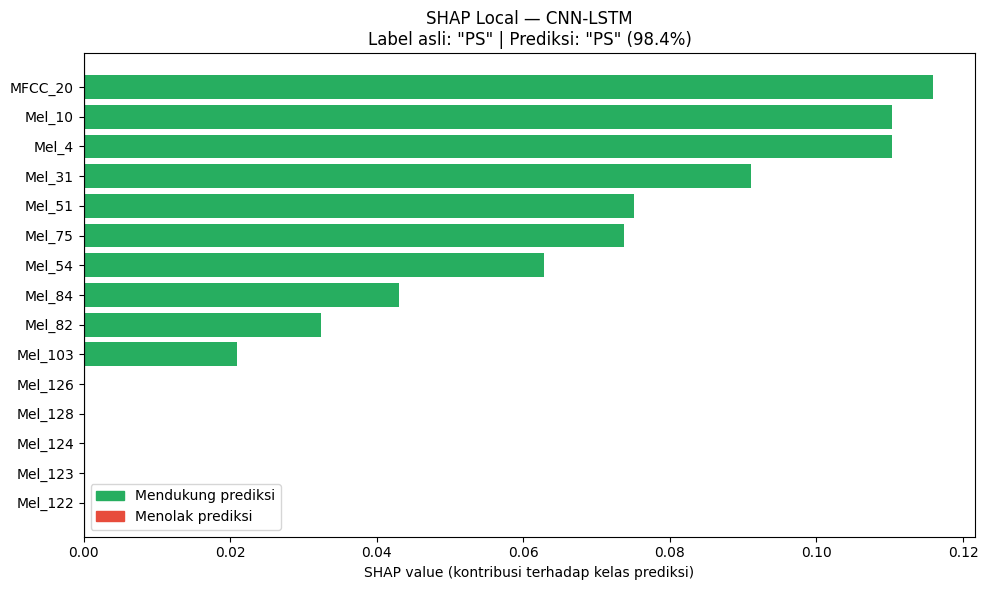

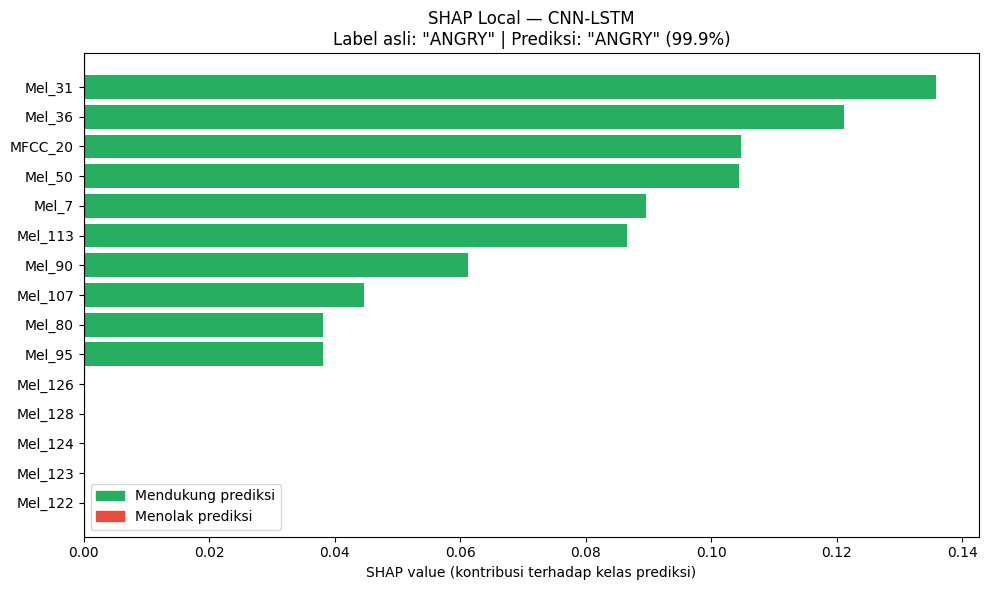

In [49]:
def shap_local_cnnlstm(sample_pos_in_explain=0):
    """
    Waterfall plot SHAP untuk 1 sampel (CNN-LSTM).
    sample_pos_in_explain: index dalam x_explain (0 s/d N_EXPLAIN-1)
    """
    true_label  = y_explain[sample_pos_in_explain]
    probs       = cnn_lstm_predict_proba(x_explain[sample_pos_in_explain].reshape(1,-1))[0]
    pred_label  = LABEL_NAMES[np.argmax(probs)]
    pred_class_idx = np.argmax(probs)

    sv          = shap_values_cnn[sample_pos_in_explain, :, pred_class_idx]  # (n_features,)
    top_feat_idx = np.argsort(np.abs(sv))[-15:][::-1]

    fig, ax = plt.subplots(figsize=(10, 6))
    colors  = ['#27ae60' if v > 0 else '#e74c3c' for v in sv[top_feat_idx]]
    ax.barh(
        [FEATURE_NAMES[i] for i in top_feat_idx][::-1],
        sv[top_feat_idx][::-1],
        color = colors[::-1]
    )
    ax.axvline(x=0, color='black', linewidth=0.8)
    ax.set_title(
        f'SHAP Local — CNN-LSTM\nLabel asli: "{true_label.upper()}" | Prediksi: "{pred_label.upper()}" ({probs.max()*100:.1f}%)',
        fontsize=12
    )
    ax.set_xlabel('SHAP value (kontribusi terhadap kelas prediksi)')
    import matplotlib.patches as mpatches
    green_p = mpatches.Patch(color='#27ae60', label='Mendukung prediksi')
    red_p   = mpatches.Patch(color='#e74c3c', label='Menolak prediksi')
    ax.legend(handles=[green_p, red_p])
    plt.tight_layout()
    plt.show()


print("SHAP Local Explanation — CNN-LSTM")
shap_local_cnnlstm(sample_pos_in_explain=0)
shap_local_cnnlstm(sample_pos_in_explain=1)

SVM

In [50]:
shap_explainer_svm = shap.KernelExplainer(
    model = svm_predict_proba,
    data  = shap.kmeans(x_background, 20)
)

shap_values_svm_raw = shap_explainer_svm.shap_values(
    x_explain, nsamples=200, silent=True
)

if isinstance(shap_values_svm_raw, list):
    shap_values_svm = np.stack(shap_values_svm_raw, axis=-1)
else:
    shap_values_svm = shap_values_svm_raw

print(f"✅ SHAP SVM selesai — shape: {shap_values_svm.shape}")

✅ SHAP SVM selesai — shape: (50, 160, 7)


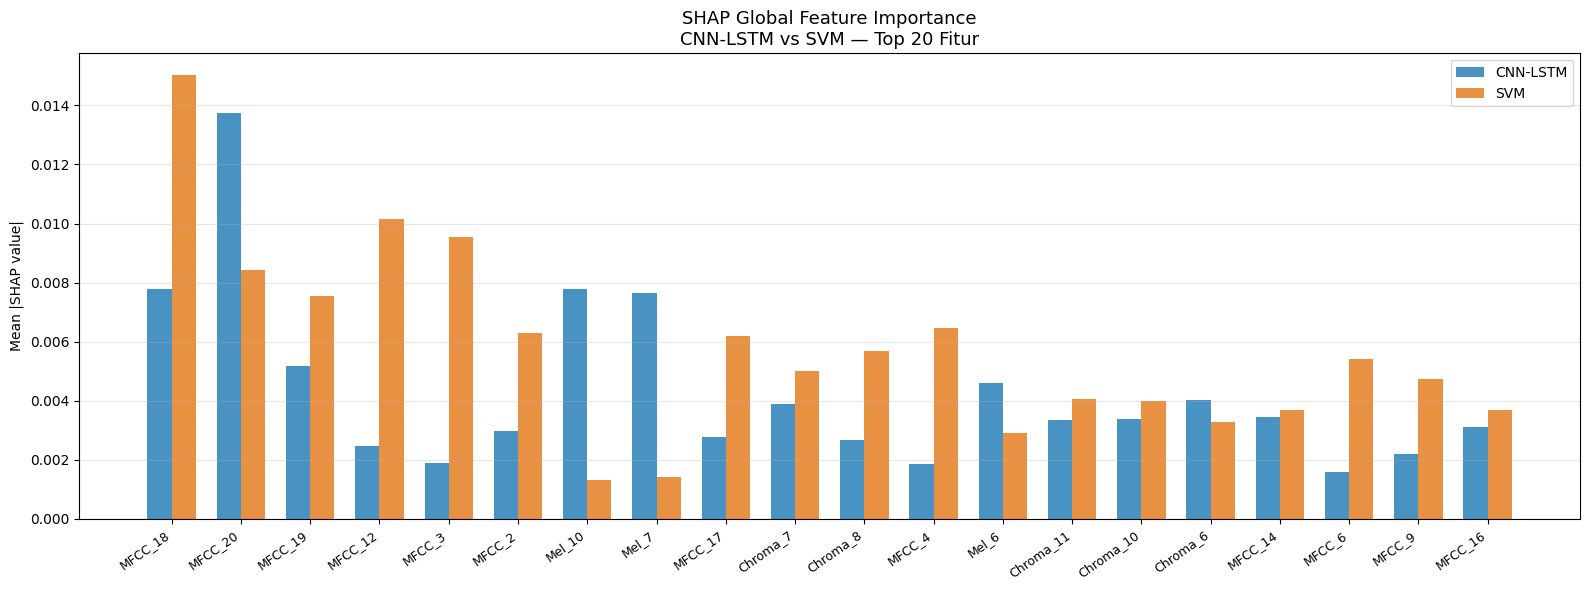


📊 Perbandingan Kelompok Fitur — CNN-LSTM vs SVM:

Kelompok            CNN-LSTM          SVM
---------------------------------------------
 Chroma (12)         0.002658     0.003392
 MFCC (20)           0.003265     0.005477
 Mel (128)           0.001521     0.000996


In [51]:
global_imp_cnn = np.mean(np.abs(shap_values_cnn), axis=(0, 2))
global_imp_svm = np.mean(np.abs(shap_values_svm), axis=(0, 2))

# Top 20 fitur berdasarkan rata-rata kedua model
combined_imp = (global_imp_cnn + global_imp_svm) / 2
top20_combined = np.argsort(combined_imp)[-20:][::-1]

x_pos     = np.arange(20)
width     = 0.35
top_names = [FEATURE_NAMES[i] for i in top20_combined]

fig, ax = plt.subplots(figsize=(16, 6))
b1 = ax.bar(x_pos - width/2, global_imp_cnn[top20_combined], width, label='CNN-LSTM', color='#2980b9', alpha=0.85)
b2 = ax.bar(x_pos + width/2, global_imp_svm[top20_combined], width, label='SVM',      color='#e67e22', alpha=0.85)
ax.set_xticks(x_pos)
ax.set_xticklabels(top_names, rotation=35, ha='right', fontsize=9)
ax.set_ylabel('Mean |SHAP value|')
ax.set_title('SHAP Global Feature Importance\nCNN-LSTM vs SVM — Top 20 Fitur', fontsize=13)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Kelompok fitur mana yang lebih penting di tiap model?
print("\n📊 Perbandingan Kelompok Fitur — CNN-LSTM vs SVM:")
groups = {
    'Chroma (12)' : (slice(0, 12),),
    'MFCC (20)'   : (slice(12, 32),),
    'Mel (128)'   : (slice(32, 160),)
}
print(f"\n{'Kelompok':<15} {'CNN-LSTM':>12} {'SVM':>12}")
print('-' * 45)
for name, (slc,) in groups.items():
    cnn_g = global_imp_cnn[slc].mean()
    svm_g = global_imp_svm[slc].mean()
    print(f" {name:<15} {cnn_g:>12.6f} {svm_g:>12.6f}")

EKSPLORASI HASIL

  [CNN-LSTM] Emosi 'angry' → fitur dominan: MFCC/Spektral (score: 0.003327)
  [SVM] Emosi 'angry' → fitur dominan: MFCC/Spektral (score: 0.004957)
  [CNN-LSTM] Emosi 'happy' → fitur dominan: MFCC/Spektral (score: 0.003816)
  [SVM] Emosi 'happy' → fitur dominan: MFCC/Spektral (score: 0.006416)


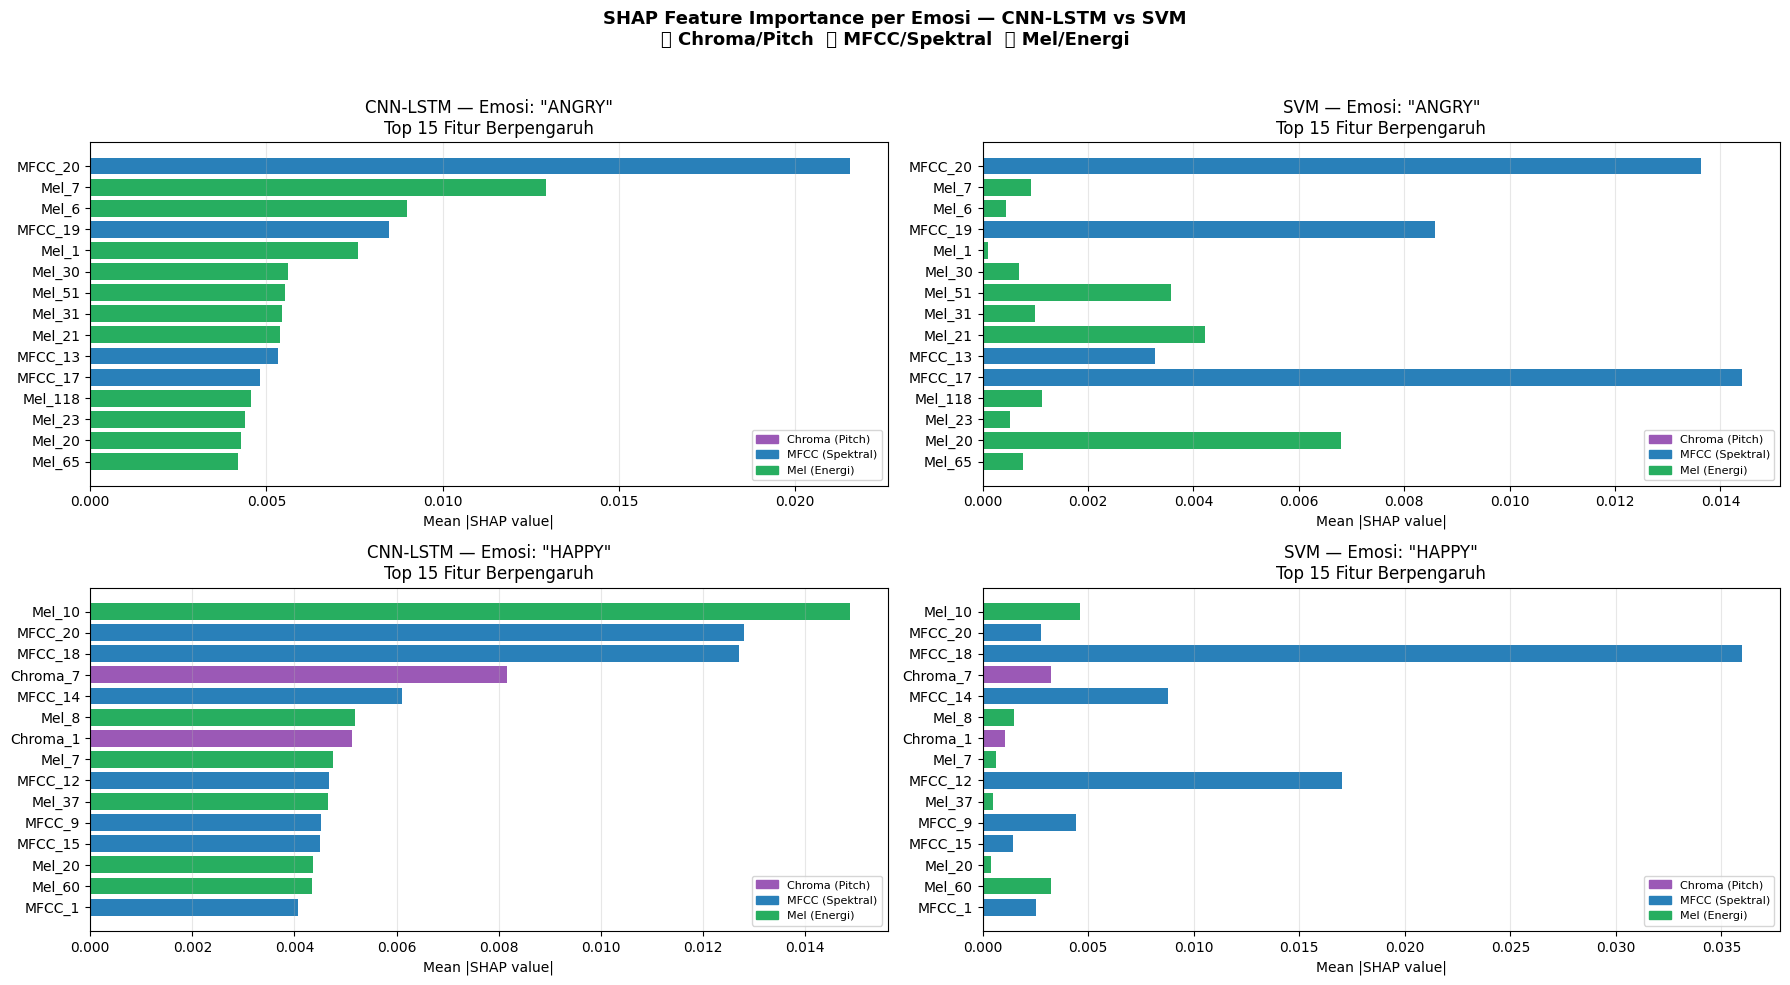

In [52]:
import matplotlib.patches as mpatches

TARGET_EMOTIONS = ['angry', 'happy']

fig, axes = plt.subplots(len(TARGET_EMOTIONS), 2, figsize=(18, 5 * len(TARGET_EMOTIONS)))

for row, emotion in enumerate(TARGET_EMOTIONS):
    emo_idx = np.where(LABEL_NAMES == emotion)[0][0]


    sv_emo_cnn = shap_values_cnn[:, :, emo_idx]
    sv_emo_svm = shap_values_svm[:, :, emo_idx]

    # --- Top 15 fitur berdasarkan mean |SHAP| CNN-LSTM
    imp_cnn = np.abs(sv_emo_cnn).mean(axis=0)
    imp_svm = np.abs(sv_emo_svm).mean(axis=0)
    top15   = np.argsort(imp_cnn)[-15:][::-1]

    top_names = [FEATURE_NAMES[i] for i in top15]
    top_cnn   = imp_cnn[top15]
    top_svm   = imp_svm[top15]

    # --- Warna berdasarkan kelompok fitur ---
    def feat_color(name):
        if name.startswith('Chroma'): return '#9b59b6'
        if name.startswith('MFCC'):   return '#2980b9'
        return '#27ae60'

    bar_colors = [feat_color(n) for n in top_names]

    # --- Plot CNN-LSTM ---
    ax = axes[row][0]
    bars = ax.barh(top_names[::-1], top_cnn[::-1], color=bar_colors[::-1])
    ax.set_title(f'CNN-LSTM — Emosi: "{emotion.upper()}"\nTop 15 Fitur Berpengaruh', fontsize=12)
    ax.set_xlabel('Mean |SHAP value|')
    purple = mpatches.Patch(color='#9b59b6', label='Chroma (Pitch)')
    blue   = mpatches.Patch(color='#2980b9', label='MFCC (Spektral)')
    green  = mpatches.Patch(color='#27ae60', label='Mel (Energi)')
    ax.legend(handles=[purple, blue, green], fontsize=8, loc='lower right')
    ax.grid(axis='x', alpha=0.3)

    # --- Plot SVM ---
    ax2 = axes[row][1]
    ax2.barh(top_names[::-1], top_svm[::-1], color=bar_colors[::-1])
    ax2.set_title(f'SVM — Emosi: "{emotion.upper()}"\nTop 15 Fitur Berpengaruh', fontsize=12)
    ax2.set_xlabel('Mean |SHAP value|')
    ax2.legend(handles=[purple, blue, green], fontsize=8, loc='lower right')
    ax2.grid(axis='x', alpha=0.3)

    for model_name, imp in [('CNN-LSTM', imp_cnn), ('SVM', imp_svm)]:
        g_chroma = imp[:12].mean()
        g_mfcc   = imp[12:32].mean()
        g_mel    = imp[32:].mean()
        dominant = max([('Chroma/Pitch', g_chroma), ('MFCC/Spektral', g_mfcc), ('Mel/Energi', g_mel)], key=lambda x: x[1])
        print(f"  [{model_name}] Emosi '{emotion}' → fitur dominan: {dominant[0]} (score: {dominant[1]:.6f})")

plt.suptitle(
    'SHAP Feature Importance per Emosi — CNN-LSTM vs SVM\n'
    '🟣 Chroma/Pitch  🔵 MFCC/Spektral  🟢 Mel/Energi',
    fontsize=13, fontweight='bold'
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [53]:
HUMAN_PERCEPTION = {
    'angry'  : {'Mel/Energi': 'tinggi', 'Chroma/Pitch': 'naik',    'MFCC/Spektral': 'tinggi'},
    'happy'  : {'Mel/Energi': 'tinggi', 'Chroma/Pitch': 'naik',    'MFCC/Spektral': 'variatif'},
    'sad'    : {'Mel/Energi': 'rendah', 'Chroma/Pitch': 'turun',   'MFCC/Spektral': 'rendah'},
    'neutral': {'Mel/Energi': 'sedang', 'Chroma/Pitch': 'stabil',  'MFCC/Spektral': 'sedang'},
    'fear'   : {'Mel/Energi': 'sedang', 'Chroma/Pitch': 'tinggi',  'MFCC/Spektral': 'tinggi'},
    'disgust': {'Mel/Energi': 'sedang', 'Chroma/Pitch': 'rendah',  'MFCC/Spektral': 'rendah'},
    'ps'     : {'Mel/Energi': 'tinggi', 'Chroma/Pitch': 'naik',    'MFCC/Spektral': 'tinggi'},
}

print("="*65)
print("  PERTANYAAN 3: Apakah Model Cocok dengan Persepsi Manusia?")
print("="*65)

# Hitung mean SHAP
for emotion in TARGET_EMOTIONS:
    emo_idx = np.where(LABEL_NAMES == emotion)[0][0]
    sv      = shap_values_cnn[:, :, emo_idx]

    mean_shap_chroma = sv[:, :12].mean()
    mean_shap_mfcc   = sv[:, 12:32].mean()
    mean_shap_mel    = sv[:, 32:].mean()

    # Interpretasi arah model
    def interpret_direction(val):
        if   val >  0.001: return 'tinggi ↑ (mendukung)'
        elif val < -0.001: return 'rendah ↓ (menolak)'
        else:              return 'netral →'

    model_interp = {
        'Mel/Energi'   : interpret_direction(mean_shap_mel),
        'Chroma/Pitch' : interpret_direction(mean_shap_chroma),
        'MFCC/Spektral': interpret_direction(mean_shap_mfcc),
    }
    human_exp = HUMAN_PERCEPTION.get(emotion, {})

    print(f"\n🎭 Emosi: {emotion.upper()}")
    print(f"  {'Fitur':<20} {'Persepsi Manusia':<20} {'Model (SHAP)':<25} {'Cocok?'}")
    print(f"  {'-'*75}")
    for feat in ['Mel/Energi', 'Chroma/Pitch', 'MFCC/Spektral']:
        human = human_exp.get(feat, '-')
        model = model_interp[feat]

        cocok = '✅' if (('tinggi' in human and 'tinggi' in model) or
                         ('rendah' in human and 'rendah' in model) or
                         ('sedang' in human and 'netral' in model)) else '⚠️'
        print(f"  {feat:<20} {human:<20} {model:<25} {cocok}")

print("\n📝 Catatan: ✅ = model konsisten dengan persepsi manusia")
print("            ⚠️  = perlu investigasi lebih lanjut")

  PERTANYAAN 3: Apakah Model Cocok dengan Persepsi Manusia?

🎭 Emosi: ANGRY
  Fitur                Persepsi Manusia     Model (SHAP)              Cocok?
  ---------------------------------------------------------------------------
  Mel/Energi           tinggi               netral →                  ⚠️
  Chroma/Pitch         naik                 netral →                  ⚠️
  MFCC/Spektral        tinggi               netral →                  ⚠️

🎭 Emosi: HAPPY
  Fitur                Persepsi Manusia     Model (SHAP)              Cocok?
  ---------------------------------------------------------------------------
  Mel/Energi           tinggi               netral →                  ⚠️
  Chroma/Pitch         naik                 netral →                  ⚠️
  MFCC/Spektral        variatif             netral →                  ⚠️

📝 Catatan: ✅ = model konsisten dengan persepsi manusia
            ⚠️  = perlu investigasi lebih lanjut


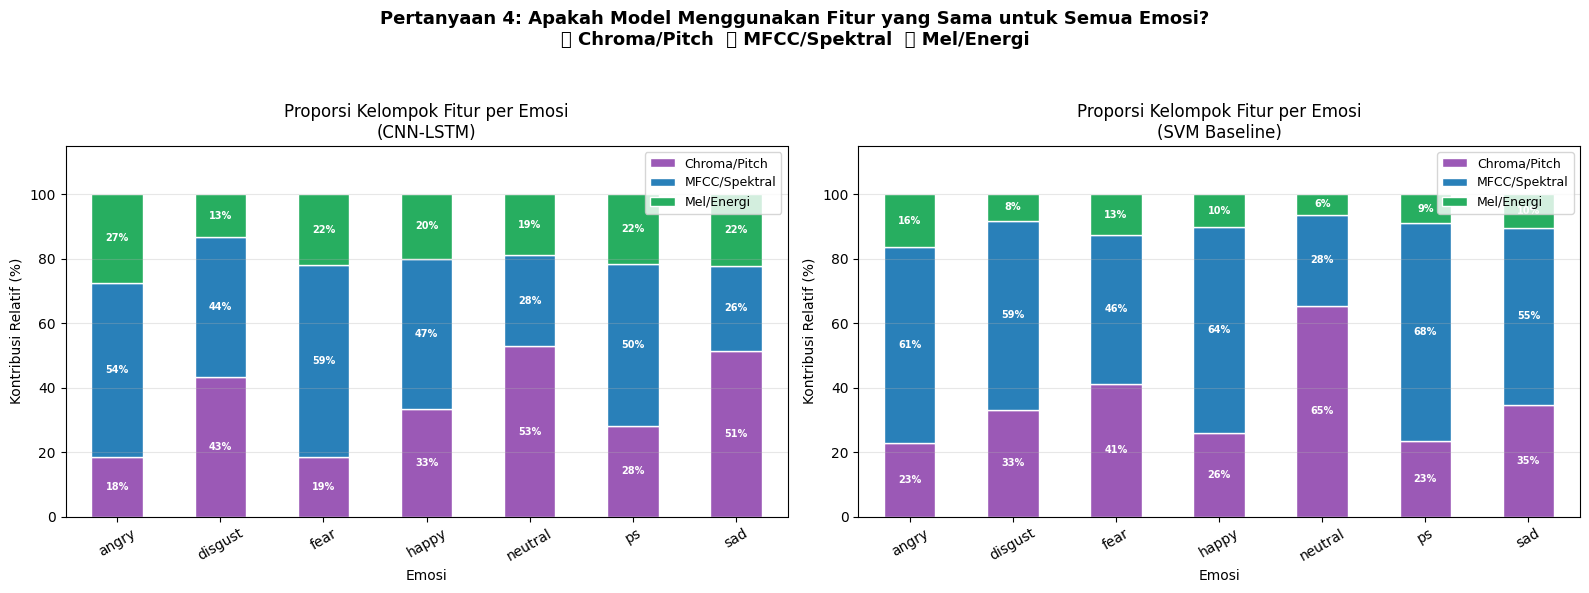


📊 CNN-LSTM — Proporsi kelompok fitur per emosi (%):


,Chroma/Pitch,MFCC/Spektral,Mel/Energi
angry,18.5,54.1,27.4
disgust,43.2,43.5,13.3
fear,18.5,59.4,22.1
happy,33.4,46.6,19.9
neutral,52.8,28.2,19.0
ps,28.0,50.3,21.7
sad,51.4,26.4,22.2



📊 SVM — Proporsi kelompok fitur fitur per emosi (%):


,Chroma/Pitch,MFCC/Spektral,Mel/Energi
angry,23.0,60.6,16.5
disgust,33.0,58.8,8.2
fear,41.1,46.2,12.6
happy,25.8,64.0,10.2
neutral,65.2,28.4,6.3
ps,23.4,67.7,8.9
sad,34.5,55.2,10.3


In [54]:
group_per_emotion_cnn = []
group_per_emotion_svm = []

for emo_idx in range(len(LABEL_NAMES)):
    sv_cnn_class = np.mean(np.abs(shap_values_cnn[:, :, emo_idx]), axis=0)
    sv_svm_class = np.mean(np.abs(shap_values_svm[:, :, emo_idx]), axis=0)

    group_per_emotion_cnn.append([
        sv_cnn_class[:12].mean(),    # Chroma
        sv_cnn_class[12:32].mean(),  # MFCC
        sv_cnn_class[32:].mean()     # Mel
    ])
    group_per_emotion_svm.append([
        sv_svm_class[:12].mean(),
        sv_svm_class[12:32].mean(),
        sv_svm_class[32:].mean()
    ])

group_df_cnn = pd.DataFrame(group_per_emotion_cnn,
                            index=LABEL_NAMES,
                            columns=['Chroma/Pitch', 'MFCC/Spektral', 'Mel/Energi'])
group_df_svm = pd.DataFrame(group_per_emotion_svm,
                            index=LABEL_NAMES,
                            columns=['Chroma/Pitch', 'MFCC/Spektral', 'Mel/Energi'])

# Normalisasi per baris (per emosi)
group_df_cnn_norm = group_df_cnn.div(group_df_cnn.sum(axis=1), axis=0) * 100
group_df_svm_norm = group_df_svm.div(group_df_svm.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# CNN-LSTM
group_df_cnn_norm.plot(
    kind='bar', ax=axes[0], stacked=True,
    color=['#9b59b6', '#2980b9', '#27ae60'], edgecolor='white'
)
axes[0].set_title('Proporsi Kelompok Fitur per Emosi\n(CNN-LSTM)', fontsize=12)
axes[0].set_ylabel('Kontribusi Relatif (%)')
axes[0].set_xlabel('Emosi')
axes[0].tick_params(axis='x', rotation=30)
axes[0].set_ylim(0, 115)
axes[0].legend(loc='upper right', fontsize=9)
axes[0].grid(axis='y', alpha=0.3)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.0f%%', label_type='center', fontsize=7, color='white', fontweight='bold')

# SVM
group_df_svm_norm.plot(
    kind='bar', ax=axes[1], stacked=True,
    color=['#9b59b6', '#2980b9', '#27ae60'], edgecolor='white'
)
axes[1].set_title('Proporsi Kelompok Fitur per Emosi\n(SVM Baseline)', fontsize=12)
axes[1].set_ylabel('Kontribusi Relatif (%)')
axes[1].set_xlabel('Emosi')
axes[1].tick_params(axis='x', rotation=30)
axes[1].set_ylim(0, 115)
axes[1].legend(loc='upper right', fontsize=9)
axes[1].grid(axis='y', alpha=0.3)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.0f%%', label_type='center', fontsize=7, color='white', fontweight='bold')

plt.suptitle(
    'Pertanyaan 4: Apakah Model Menggunakan Fitur yang Sama untuk Semua Emosi?\n'
    '🟣 Chroma/Pitch  🔵 MFCC/Spektral  🟢 Mel/Energi',
    fontsize=13, fontweight='bold'
)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

print("\n📊 CNN-LSTM — Proporsi kelompok fitur per emosi (%):")
display(group_df_cnn_norm.round(1))

print("\n📊 SVM — Proporsi kelompok fitur fitur per emosi (%):")
display(group_df_svm_norm.round(1))

#PENYEBAB KESALAHAN

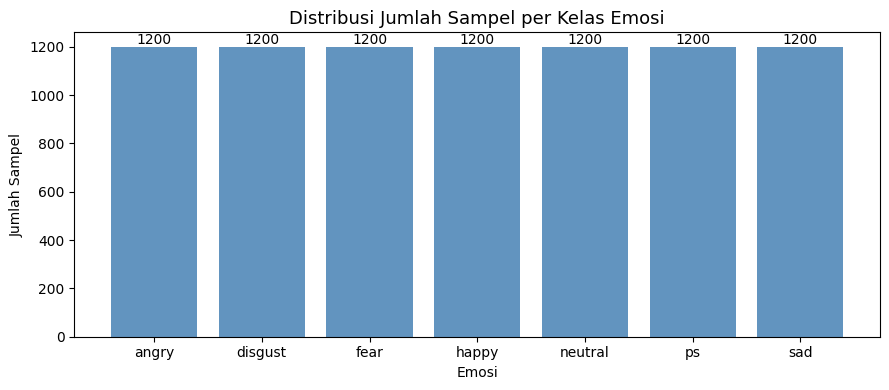

Kelas terbanyak : angry (1200 sampel)
Kelas tersedikit: angry (1200 sampel)
Rasio imbalance : 1.00x


In [55]:
# 1. Cek distribusi kelas — apakah data seimbang?
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

label_counts = pd.Series(Y.argmax(axis=1)).value_counts().sort_index()
label_counts.index = label_names

plt.figure(figsize=(9, 4))
bars = plt.bar(label_counts.index, label_counts.values, color='steelblue', alpha=0.85)
for bar, val in zip(bars, label_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
             str(val), ha='center', fontsize=10)
plt.title('Distribusi Jumlah Sampel per Kelas Emosi', fontsize=13)
plt.xlabel('Emosi')
plt.ylabel('Jumlah Sampel')
plt.tight_layout()
plt.show()

# Hitung rasio imbalance
max_count = label_counts.max()
min_count = label_counts.min()
print(f"Kelas terbanyak : {label_counts.idxmax()} ({max_count} sampel)")
print(f"Kelas tersedikit: {label_counts.idxmin()} ({min_count} sampel)")
print(f"Rasio imbalance : {max_count / min_count:.2f}x")

In [56]:
# 2. Emosi yang paling sering tertukar dari confusion matrix CNN-LSTM
cm = cm_cnn.copy()
np.fill_diagonal(cm, 0)

confusion_pairs = []
for i in range(len(label_names)):
    for j in range(len(label_names)):
        if i != j and cm[i, j] > 0:
            confusion_pairs.append({
                'True': label_names[i],
                'Predicted': label_names[j],
                'Count': cm[i, j]
            })

confusion_df = pd.DataFrame(confusion_pairs).sort_values('Count', ascending=False)
print("Top 10 Pasangan Emosi yang Paling Sering Tertukar (CNN-LSTM):")
print(confusion_df.head(10).to_string(index=False))

Top 10 Pasangan Emosi yang Paling Sering Tertukar (CNN-LSTM):
   True Predicted  Count
disgust        ps      3
disgust     happy      2
  happy        ps      2
     ps     happy      2
disgust   neutral      1
  angry     happy      1
  angry   disgust      1
     ps     angry      1


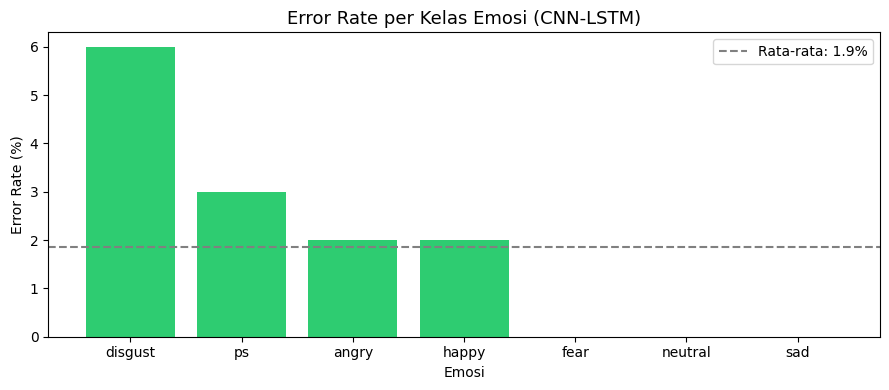

         Error Rate (%)
disgust             6.0
ps                  3.0
angry               2.0
happy               2.0
fear                0.0
neutral             0.0
sad                 0.0


In [57]:
# 3. Error rate per kelas emosi
error_rate = {}
for i, emotion in enumerate(label_names):
    total = cm_cnn[i].sum()
    correct = cm_cnn[i, i]
    error_rate[emotion] = (total - correct) / total * 100

error_df = pd.DataFrame.from_dict(error_rate, orient='index', columns=['Error Rate (%)'])
error_df = error_df.sort_values('Error Rate (%)', ascending=False)

plt.figure(figsize=(9, 4))
bars = plt.bar(error_df.index, error_df['Error Rate (%)'],
               color=['#e74c3c' if v > 30 else '#e67e22' if v > 15 else '#2ecc71'
                      for v in error_df['Error Rate (%)']])
plt.axhline(y=error_df['Error Rate (%)'].mean(), color='gray',
            linestyle='--', label=f"Rata-rata: {error_df['Error Rate (%)'].mean():.1f}%")
plt.title('Error Rate per Kelas Emosi (CNN-LSTM)', fontsize=13)
plt.ylabel('Error Rate (%)')
plt.xlabel('Emosi')
plt.legend()
plt.tight_layout()
plt.show()

print(error_df.round(1))

In [58]:
most_confused_pair = confusion_df.iloc[0]

emo1_name = most_confused_pair['True']
emo2_name = most_confused_pair['Predicted']
count     = most_confused_pair['Count']

print(f"Pasangan emosi yang paling sering tertukar (CNN-LSTM): '{emo1_name.upper()}' dan '{emo2_name.upper()}' (tertukar {count} kali).")

if 'data_path' not in locals() or data_path.empty:
    data = []
    for file_path in audio_files:
        folder_name = os.path.basename(os.path.dirname(file_path))
        file_name = os.path.basename(file_path)
        emotion = extract_emotion_from_folder(folder_name)
        gender = extract_gender_from_folder_or_file(folder_name)
        if emotion is not None:
            data.append({
                "emotion": emotion,
                "gender": gender,
                "path": file_path,
                "file_name": file_name,
                "folder": folder_name
            })
    data_path = pd.DataFrame(data)


file_emo1 = data_path[data_path['emotion'] == emo1_name]['path'].iloc[0]
file_emo2 = data_path[data_path['emotion'] == emo2_name]['path'].iloc[0]

print(f"\nContoh file untuk '{emo1_name}': {os.path.basename(file_emo1)}")
print(f"Contoh file untuk '{emo2_name}': {os.path.basename(file_emo2)}")


Pasangan emosi yang paling sering tertukar (CNN-LSTM): 'DISGUST' dan 'PS' (tertukar 3 kali).

Contoh file untuk 'disgust': OAF_burn_disgust.wav
Contoh file untuk 'ps': OAF_keg_ps.wav


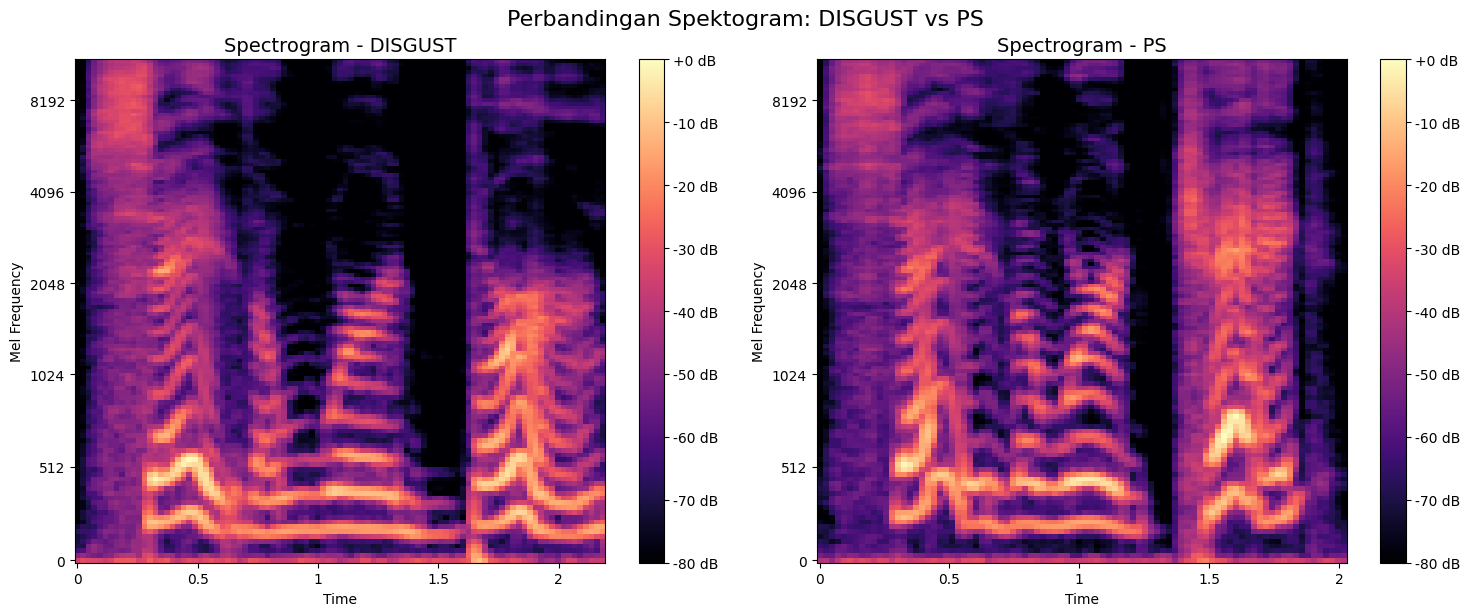

In [59]:
def plot_spectrogram_comparison(file_path1, emotion1, file_path2, emotion2, sr=22050):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # Load audio 1
    data1, sr1 = librosa.load(file_path1, sr=sr)
    spectrogram1 = librosa.feature.melspectrogram(y=data1, sr=sr1, n_mels=128, fmax=8000)
    log_spectrogram1 = librosa.power_to_db(spectrogram1, ref=np.max)

    # Plot spectrogram 1
    librosa.display.specshow(log_spectrogram1, y_axis='mel', sr=sr1, x_axis='time', ax=axes[0])
    axes[0].set_title(f'Spectrogram - {emotion1.upper()}', fontsize=14)
    axes[0].set_xlabel('Time')
    axes[0].set_ylabel('Mel Frequency')
    fig.colorbar(axes[0].collections[0], format='%+2.0f dB', ax=axes[0])

    # Load audio 2
    data2, sr2 = librosa.load(file_path2, sr=sr)
    spectrogram2 = librosa.feature.melspectrogram(y=data2, sr=sr2, n_mels=128, fmax=8000)
    log_spectrogram2 = librosa.power_to_db(spectrogram2, ref=np.max)

    # Plot spectrogram 2
    librosa.display.specshow(log_spectrogram2, y_axis='mel', sr=sr2, x_axis='time', ax=axes[1])
    axes[1].set_title(f'Spectrogram - {emotion2.upper()}', fontsize=14)
    axes[1].set_xlabel('Time')
    axes[1].set_ylabel('Mel Frequency')
    fig.colorbar(axes[1].collections[0], format='%+2.0f dB', ax=axes[1])

    plt.tight_layout()
    plt.suptitle(f"Perbandingan Spektogram: {emotion1.upper()} vs {emotion2.upper()}", fontsize=16, y=1.02)
    plt.show()

plot_spectrogram_comparison(file_emo1, emo1_name, file_emo2, emo2_name)